Training & Validasi FCN (SEGMENTASI MASK) 

In [1]:
import os
import json
import numpy as np
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import time
import glob
from pycocotools.coco import COCO
import pycocotools.mask as maskUtils
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.data import AUTOTUNE
import keras_tuner as kt
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf
import time
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
from matplotlib.colors import ListedColormap, BoundaryNorm 
tf.get_logger().setLevel('ERROR')
print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.19.1


Konfigurasi

In [2]:
ROOT_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"

# Path untuk folder Train
TRAIN_IMG_DIR = os.path.join(ROOT_DIR, 'train')
TRAIN_ANNOTATION_FILE = os.path.join(ROOT_DIR, 'train', 'train_annotations.coco.json')

# Path untuk folder Valid
VALID_IMG_DIR = os.path.join(ROOT_DIR, 'valid')
VALID_ANNOTATION_FILE = os.path.join(ROOT_DIR, 'valid', 'valid_annotations.coco.json')

# Path untuk folder Test
TEST_IMG_DIR = os.path.join(ROOT_DIR, 'test')
TEST_ANNOTATION_FILE = os.path.join(ROOT_DIR, 'test', 'test_annotations.coco.json')

# Konfigurasi Model
IMG_HEIGHT = 256
IMG_WIDTH = 256
IMG_CHANNELS = 3

# Konfigurasi Training
EPOCHS_TUNING = 10       # Jumlah epoch per trial saat tuning (samakan segementasi = 6)
EPOCHS_FINAL = 50        # Jumlah epoch untuk training model final (samakan segementasi =30)
PATIENCE_EARLYSTOP = 5   # Toleransi (epoch) sebelum early stopping

print(f"Root Direktori: {ROOT_DIR}")
print(f"File Anotasi Train: {TRAIN_ANNOTATION_FILE}")
print(f"File Anotasi Valid: {VALID_ANNOTATION_FILE}")
print(f"File Anotasi Test: {TEST_ANNOTATION_FILE}")
print(f"Ukuran Input Model: ({IMG_HEIGHT}, {IMG_WIDTH})")

Root Direktori: Tanggul/eksperimen/dataset/augmentasi_mask
File Anotasi Train: Tanggul/eksperimen/dataset/augmentasi_mask\train\train_annotations.coco.json
File Anotasi Valid: Tanggul/eksperimen/dataset/augmentasi_mask\valid\valid_annotations.coco.json
File Anotasi Test: Tanggul/eksperimen/dataset/augmentasi_mask\test\test_annotations.coco.json
Ukuran Input Model: (256, 256)


Validasi COCO & Definisi Kelas

In [3]:
try:
    # Inisialisasi COCO API (Hanya untuk validasi & pemetaan)
    coco_train_val = COCO(TRAIN_ANNOTATION_FILE)
    
    # Dapatkan Kategori (Kelas) dari file JSON
    cats = coco_train_val.loadCats(coco_train_val.getCatIds())
    
    # Buat Pemetaan Kelas
    CLASS_NAMES = ['Background'] # Label 0 dicadangkan untuk "Background"
    category_map = {} # Map COCO catId -> trainId (1, 2, 3)
    
    print("\nKategori COCO Ditemukan")
    
    # Gunakan sorted() untuk menjamin urutan ID (1, 2, 3)
    for cat in sorted(cats, key=lambda k: k['id']):
        # Gunakan ID dari COCO (1, 2, 3) sebagai train_id
        train_id = cat['id'] 
        CLASS_NAMES.append(cat['name'])
        category_map[cat['id']] = train_id
        
        print(f"  COCO ID: {cat['id']}, Nama: {cat['name']} -> Train ID: {train_id}")

    # Atur Variabel Global
    NUM_CLASSES = len(CLASS_NAMES) # Total 4 (termasuk Background)
    
    print(f"\nVariabel Kelas Selesai Dibuat:")
    print(f"  NUM_CLASSES: {NUM_CLASSES}")
    print(f"  CLASS_NAMES: {CLASS_NAMES}")
    print(f"  category_map: {category_map}")
    
    del coco_train_val # Hapus dari memori

except FileNotFoundError:
    print(f"FATAL ERROR: File anotasi tidak ditemukan di {TRAIN_ANNOTATION_FILE}")
except Exception as e:
    print(f"FATAL ERROR saat memuat COCO: {e}")

loading annotations into memory...
Done (t=0.87s)
creating index...
index created!

Kategori COCO Ditemukan
  COCO ID: 1, Nama: Retak-Berat -> Train ID: 1
  COCO ID: 2, Nama: Retak-Ringan -> Train ID: 2
  COCO ID: 3, Nama: Tidak-Retak -> Train ID: 3

Variabel Kelas Selesai Dibuat:
  NUM_CLASSES: 4
  CLASS_NAMES: ['Background', 'Retak-Berat', 'Retak-Ringan', 'Tidak-Retak']
  category_map: {1: 1, 2: 2, 3: 3}


Generator Data Berbasis Kelas

In [4]:
class CocoDataGenerator:
    """
    Generator berbasis Kelas (Class) yang memuat COCO JSON
    hanya SATU KALI saat inisialisasi.
    """
    def __init__(self, annotation_file, is_training):
        # Muat JSON SATU KALI
        print(f"\n[Data Generator] Menginisialisasi dan memuat {os.path.basename(annotation_file)}...")
        
        self.coco = COCO(annotation_file)
        self.image_ids = list(sorted(self.coco.imgs.keys()))
        self.is_training = is_training
 
        self.base_img_dir = os.path.dirname(annotation_file) 
        
        # Ambil variabel Global
        self.category_map = category_map # Dari Cell 3
        
        print(f"[Data Generator] Anotasi dimuat. {len(self.image_ids)} gambar ditemukan.")
        print(f"[Data Generator] Path gambar diatur ke: {self.base_img_dir}")

    def __call__(self):
        """
        Fungsi __call__ ini bertindak sebagai generator.
        tf.data akan memanggil ini.
        """
        if self.is_training:
            np.random.shuffle(self.image_ids)
        
        for image_id in self.image_ids:
            try:
                # Muat Info Gambar
                img_info = self.coco.loadImgs([image_id])[0]
                
                # Gabungkan base_img_dir dengan nama file
                img_path = os.path.join(self.base_img_dir, img_info['file_name']) 
                
                # Muat Gambar (menggunakan OpenCV)
                image = cv2.imread(img_path)
                if image is None:
                    print(f"[Generator Warning] Gagal memuat {img_path}, dilewati.")
                    continue
                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # Ubah ke RGB
                
                # Render Masker
                mask = np.zeros((img_info['height'], img_info['width']), dtype=np.int32)
                ann_ids = self.coco.getAnnIds(imgIds=image_id)
                anns = self.coco.loadAnns(ann_ids)
                
                # Terapkan anotasi ke masker
                for ann in anns:
                    cat_id = ann['category_id']
                    if cat_id in self.category_map:
                        # Dapatkan train_id (1, 2, atau 3)
                        train_id = self.category_map[cat_id]
                        # Render segmentasi dari COCO
                        segment_mask = self.coco.annToMask(ann)
                        # Isi area masker dengan train_id
                        mask[segment_mask == 1] = train_id
                
                yield image.astype(np.uint8), mask.astype(np.int32)
            
            except Exception as e:
                print(f"[Generator Error] Gagal memproses img_id {image_id}: {e}")
                continue

print("Definisi CocoDataGenerator (Class)")

Definisi CocoDataGenerator (Class)


Membuat tf.data.Dataset dari Kelas Generator

In [5]:
def preprocess_and_augment(image, mask, is_training):
    """Menerapkan resize dan augmentasi (operasi TF murni)."""
    
    # Tambahkan channel dimension ke masker (H,W) -> (H,W,1)
    #    Ini diperlukan agar tf.image.resize bekerja
    mask = mask[..., tf.newaxis]
    
    # Resize
    #    'bilinear' untuk gambar (interpolasi halus)
    image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH], method='bilinear')
    #    'nearest' untuk masker (menjaga nilai 0,1,2,3)
    mask = tf.image.resize(mask, [IMG_HEIGHT, IMG_WIDTH], method='nearest')
    
    # Augmentasi (hanya saat training)
    if is_training:
        if tf.random.uniform(()) > 0.5:
            image = tf.image.flip_left_right(image)
            mask = tf.image.flip_left_right(mask)
            
    # Squeeze masker kembali ke (H,W)
    mask = tf.squeeze(mask)
    
    # Normalisasi gambar
    image = tf.cast(image, tf.float32) / 255.0
    
    return image, tf.cast(mask, tf.int32)

print("Fungsi preprocess_and_augment")

# Buat Instance Generator SATU KALI
# Ini akan memuat JSON 3x (satu kali untuk train, valid, test)
try:
    train_gen_instance = CocoDataGenerator(TRAIN_ANNOTATION_FILE, is_training=True)
    valid_gen_instance = CocoDataGenerator(VALID_ANNOTATION_FILE, is_training=False)
    test_gen_instance = CocoDataGenerator(TEST_ANNOTATION_FILE, is_training=False)
except Exception as e:
    print(f"FATAL: Gagal inisialisasi generator Error: {e}")

# Fungsi baru untuk membuat dataset dari INSTANCE
def create_coco_dataset(generator_instance, is_training=True):
    """Membuat pipeline tf.data dari INSTANCE generator."""
    
    dataset_size = len(generator_instance.image_ids)
    print(f"Membuat dataset dari generator ({dataset_size} gambar)")

    # Buat dataset dari generator
    dataset = tf.data.Dataset.from_generator(
        generator_instance, # <-- Panggil INSTANCE
        output_signature=(
            # Sesuai output yield (sebelum resize/preprocess)
            tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
            tf.TensorSpec(shape=(None, None), dtype=tf.int32)
        )
    )
    
    # Terapkan preprocessing dan augmentasi
    map_fn_pre = lambda img, msk: preprocess_and_augment(img, msk, is_training)
    dataset = dataset.map(map_fn_pre, num_parallel_calls=AUTOTUNE)
    
    return dataset, dataset_size

print("\nMembuat dataset menggunakan generator CLASS")
train_dataset, train_count = create_coco_dataset(train_gen_instance, is_training=True)
valid_dataset, valid_count = create_coco_dataset(valid_gen_instance, is_training=False)
test_dataset, test_count = create_coco_dataset(test_gen_instance, is_training=False)

# Simpan jumlah data
DATASET_COUNTS = {
    "train": train_count,
    "valid": valid_count,
    "test": test_count
}
print("\nPipeline tf.data Generator Class")

Fungsi preprocess_and_augment

[Data Generator] Menginisialisasi dan memuat train_annotations.coco.json...
loading annotations into memory...
Done (t=1.10s)
creating index...
index created!
[Data Generator] Anotasi dimuat. 4200 gambar ditemukan.
[Data Generator] Path gambar diatur ke: Tanggul/eksperimen/dataset/augmentasi_mask\train

[Data Generator] Menginisialisasi dan memuat valid_annotations.coco.json...
loading annotations into memory...
Done (t=0.39s)
creating index...
index created!
[Data Generator] Anotasi dimuat. 1800 gambar ditemukan.
[Data Generator] Path gambar diatur ke: Tanggul/eksperimen/dataset/augmentasi_mask\valid

[Data Generator] Menginisialisasi dan memuat test_annotations.coco.json...
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
[Data Generator] Anotasi dimuat. 90 gambar ditemukan.
[Data Generator] Path gambar diatur ke: Tanggul/eksperimen/dataset/augmentasi_mask\test

Membuat dataset menggunakan generator CLASS
Membuat datase

Visualisasi Sampel Data

Mencari 3 sampel untuk 3 kelas...


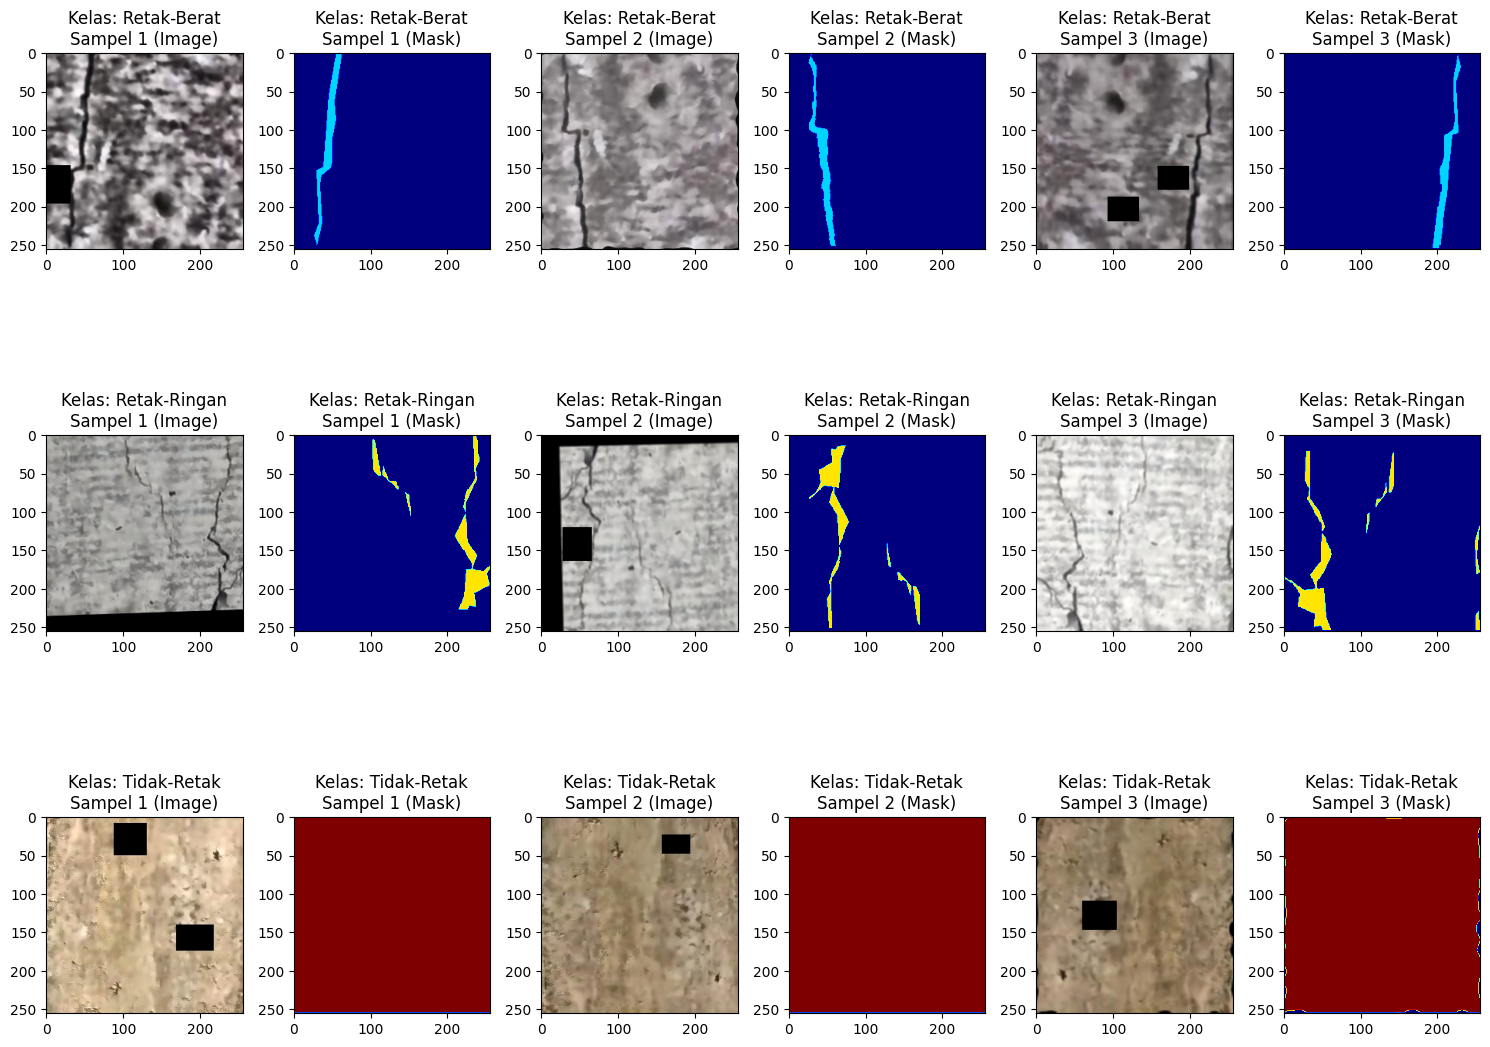

In [6]:
try:
    # Dapatkan objek COCO dari generator yang sudah ada di memori
    coco = train_gen_instance.coco 
    
    # Tentukan kelas yang ingin ditampilkan (skip 'Background')
    target_classes = CLASS_NAMES[1:] # ['Retak-Berat', 'Retak-Ringan', 'Tidak-Retak']
    
    # Buat pemetaan Nama Kelas -> ID Kategori COCO
    cat_name_to_id = {cat['name']: cat['id'] for cat in coco.cats.values()}
    
    # Siapkan figure
    num_classes_to_show = len(target_classes) # 3
    num_samples_per_class = 3
    
    fig, axes = plt.subplots(
        num_classes_to_show,          # 3 baris (satu per kelas)
        num_samples_per_class * 2,    # 6 kolom (Image, Mask, Image, Mask, ...)
        figsize=(15, 4 * num_classes_to_show) # Ukuran plot
    )
    
    print(f"Mencari {num_samples_per_class} sampel untuk {num_classes_to_show} kelas...")

    for i, class_name in enumerate(target_classes):
        cat_id = cat_name_to_id[class_name]
        
        # Dapatkan 3 ID gambar unik untuk kelas ini
        ann_ids = coco.getAnnIds(catIds=[cat_id])
        if not ann_ids:
            print(f"Peringatan: Tidak ada anotasi ditemukan untuk: {class_name}")
            continue
            
        image_ids_for_class = [coco.loadAnns(ann_id)[0]['image_id'] for ann_id in ann_ids]
        unique_image_ids = list(set(image_ids_for_class))
        
        if len(unique_image_ids) < num_samples_per_class:
            print(f"Peringatan: Hanya {len(unique_image_ids)} gambar unik ditemukan untuk {class_name}")
            image_ids_to_load = unique_image_ids
        else:
            # Ambil 3 sampel pertama
            image_ids_to_load = unique_image_ids[:num_samples_per_class]

        # 5. Loop 3 sampel, muat, proses, dan plot
        for j, image_id in enumerate(image_ids_to_load):
            
            # Replikasi Logika Loading & Preprocessing
            # Muat Gambar
            img_info = coco.loadImgs([image_id])[0]
            img_path = os.path.join(train_gen_instance.base_img_dir, img_info['file_name'])
            image = cv2.imread(img_path)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
            # Render Masker (untuk semua kelas di gambar)
            mask = np.zeros((img_info['height'], img_info['width']), dtype=np.int32)
            img_ann_ids = coco.getAnnIds(imgIds=image_id)
            anns = coco.loadAnns(img_ann_ids)
            for ann in anns:
                ann_cat_id = ann['category_id']
                if ann_cat_id in category_map:
                    train_id = category_map[ann_cat_id]
                    segment_mask = coco.annToMask(ann)
                    mask[segment_mask == 1] = train_id
            
            # Preprocess (gunakan fungsi)
            image_tensor = tf.convert_to_tensor(image, dtype=tf.uint8)
            mask_tensor = tf.convert_to_tensor(mask, dtype=tf.int32)
            
            image_processed, mask_processed = preprocess_and_augment(
                image_tensor, 
                mask_tensor, 
                is_training=False # False = jangan augmentasi (flip)
            )
            # Selesai Replikasi
            
            # 6. Plotting
            col_img = j * 2
            col_mask = j * 2 + 1
            
            # Plot Image
            ax = axes[i, col_img]
            ax.imshow(image_processed)
            ax.set_title(f"Kelas: {class_name}\nSampel {j+1} (Image)")
            ax.axis("on")
            
            # Plot Mask
            ax = axes[i, col_mask]
            ax.imshow(mask_processed, cmap='jet', vmin=0, vmax=NUM_CLASSES-1)
            ax.set_title(f"Kelas: {class_name}\nSampel {j+1} (Mask)")
            ax.axis("on")

    plt.tight_layout()
    plt.show()

except NameError as e:
    print(f"\nFATAL ERROR: Variabel tidak ditemukan: {e}")
    print("Pastikan Cell 3, 4, dan 5 sudah dijalankan.")
except Exception as e:
    print(f"\nGagal membuat visualisasi per kelas: {e}")

In [7]:
class SparseMeanIoU(tf.keras.metrics.MeanIoU):
    def __init__(self, num_classes, name='mean_iou', dtype=None, **kwargs): # Tambahkan **kwargs
        super(SparseMeanIoU, self).__init__(
            num_classes=num_classes, name=name, dtype=dtype, **kwargs # Berikan **kwargs
        )

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_pred_sparse = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
        return super().update_state(y_true, y_pred_sparse, sample_weight)

print("Metrik SparseMeanIoU telah didefinisikan")

Metrik SparseMeanIoU telah didefinisikan


Model Fully Convolutional Network (FCN)

In [8]:
def build_fcn_model_for_tuner(hp):
    """Mendefinisikan model FCN yang akan di-tuning."""
    
    inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))

    # ENCODER (ResNet50)
    backbone = keras.applications.ResNet50(
        include_top=False,
        weights='imagenet',
        input_tensor=inputs
    )
    backbone.trainable = False 
    
    c5 = backbone.get_layer('conv5_block3_out').output 
    c4 = backbone.get_layer('conv4_block6_out').output
    c3 = backbone.get_layer('conv3_block4_out').output
    
    # DECODER (FCN Head)
    filters_1 = hp.Int("filters_1", min_value=128, max_value=512, step=128)
    filters_2 = filters_1 // 2
    filters_3 = filters_1 // 4

    up_c5 = layers.Conv2DTranspose(filters_1, 4, strides=2, padding='same', activation='relu')(c5)
    skip_c4 = layers.Conv2D(filters_1, 1, padding='same', activation='relu')(c4)
    fuse_c4_c5 = layers.Add()([up_c5, skip_c4])

    up_c4_c5 = layers.Conv2DTranspose(filters_2, 4, strides=2, padding='same', activation='relu')(fuse_c4_c5)
    skip_c3 = layers.Conv2D(filters_2, 1, padding='same', activation='relu')(c3)
    fuse_c3_c4_c5 = layers.Add()([up_c4_c5, skip_c3])

    u1 = layers.Conv2DTranspose(filters_3, 4, strides=2, padding='same', activation='relu')(fuse_c3_c4_c5)
    u2 = layers.Conv2DTranspose(filters_3 // 2, 4, strides=2, padding='same', activation='relu')(u1)
    u3 = layers.Conv2DTranspose(filters_3 // 4, 4, strides=2, padding='same', activation='relu')(u2)

    outputs = layers.Conv2D(NUM_CLASSES, 1, padding='same', activation='softmax', name='segmentation_output')(u3)
    
    model = keras.Model(inputs=inputs, outputs=outputs, name="FCN_ResNet50")
    
    lr = hp.Choice("lr", [1e-3, 5e-4, 1e-4])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), 
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
            SparseMeanIoU(num_classes=NUM_CLASSES, name="mean_iou") # Metrik kustom
        ]
    )
    return model

early_stopping_cb = keras.callbacks.EarlyStopping(
    monitor="val_mean_iou",   
    mode="max",               
    patience=PATIENCE_EARLYSTOP, 
    restore_best_weights=True
)

# Visualisasi Arsitektur
try:
    hp = kt.HyperParameters()
    hp.Choice("lr", [1e-3, 5e-4, 1e-4])
    hp.Int("filters_1", min_value=128, max_value=512, step=128)
    sample_hp = hp.copy()
    sample_hp.values['lr'] = 1e-4
    sample_hp.values['filters_1'] = 128
    
    sample_model = build_fcn_model_for_tuner(sample_hp)
    print("\nModel Summary")
    sample_model.summary(line_length=120)
    
    tf.keras.utils.plot_model(sample_model, to_file="fcn_architecture_coco.png", show_shapes=True, dpi=70)
    print("Arsitektur juga berhasil disimpan sebagai 'fcn_architecture_coco.png'")
    
except NameError as e:
    print(f"\nFATAL: Variabel dari Cell 2/3 tidak ditemukan: {e}")
except Exception as e:
    print(f"\nTerjadi error saat membuat visualisasi: {e}")


Model Summary


Model: "FCN_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                      ┃ Output Shape                 ┃           Param # ┃ Connected to              
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━
│ input_layer (InputLayer)          │ (None, 256, 256, 3)          │                 0 │ -                         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv1_pad (ZeroPadding2D)         │ (None, 262, 262, 3)          │                 0 │ input_layer[0][0]         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv1_conv (Conv2D)               │ (None, 128, 128, 64)         │             9,472 │ conv1_pad[0][0]           
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv1_bn (BatchNormalization)     │ (None, 128, 128, 64)         │               256 │ conv1_conv[0][0]          
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv1_relu (Activation)           │ (None, 128, 128, 64)         │                 0 │ conv1_bn[0][0]            
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ pool1_pad (ZeroPadding2D)         │ (None, 130, 130, 64)         │                 0 │ conv1_relu[0][0]          
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ pool1_pool (MaxPooling2D)         │ (None, 64, 64, 64)           │                 0 │ pool1_pad[0][0]           
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_1_conv (Conv2D)      │ (None, 64, 64, 64)           │             4,160 │ pool1_pool[0][0]          
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_1_bn                 │ (None, 64, 64, 64)           │               256 │ conv2_block1_1_conv[0][0] 
│ (BatchNormalization)              │                              │                   │                           
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_1_relu (Activation)  │ (None, 64, 64, 64)           │                 0 │ conv2_block1_1_bn[0][0]   
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_2_conv (Conv2D)      │ (None, 64, 64, 64)           │            36,928 │ conv2_block1_1_relu[0][0] 
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_2_bn                 │ (None, 64, 64, 64)           │               256 │ conv2_block1_2_conv[0][0] 
│ (BatchNormalization)              │                              │                   │                           
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_2_relu (Activation)  │ (None, 64, 64, 64)           │                 0 │ conv2_block1_2_bn[0][0]   
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_0_conv (Conv2D)      │ (None, 64, 64, 256)          │            16,640 │ pool1_pool[0][0]          
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_3_conv (Conv2D)      │ (None, 64, 64, 256)          │            16,640 │ conv2_block1_2_relu[0][0] 
├───────────────────────────────────┼───────────────────

 Total params: 28,120,412 (107.27 MB)

 Trainable params: 4,532,700 (17.29 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.
Arsitektur juga berhasil disimpan sebagai 'fcn_architecture_coco.png'


Hyperparameter Tuning Trial

In [9]:
print("Memulai Hyperparameter Tuning Trial")
start_time = time.time() 

# Tentukan Search Space
hp_filters_list = [128, 256, 512]     # 3 pilihan filter
hp_lr_list = [1e-3, 5e-4, 1e-4]       # 3 pilihan learning rate
hp_batch_list = [8, 16]              # 2 pilihan batch size
total_trials = len(hp_filters_list) * len(hp_lr_list) * len(hp_batch_list)
print(f"Total trial yang akan dijalankan: {total_trials} (sekitar {EPOCHS_TUNING} epoch per trial)")

# Siapkan Penyimpanan Hasil
results_log = []
best_val_iou = -1.0
best_hps = {}
best_model = None # Simpan model terbaik di memori

# Mulai Manual Loop
trial_num = 1
for filters in hp_filters_list:
    for lr in hp_lr_list:
        for batch_size in hp_batch_list:
            
            print(f"\nMENJALANKAN TRIAL #{trial_num}/{total_trials}")
            print(f"HP: Filters={filters}, LR={lr}, BatchSize={batch_size}")

            # Buat model dengan HP saat ini
            hp = kt.HyperParameters()
            hp.values['filters_1'] = filters
            hp.values['lr'] = lr
            model = build_fcn_model_for_tuner(hp)

            # Buat dataset dengan batch size
            train_ds_tuned = train_dataset.shuffle(1024).batch(batch_size).repeat().prefetch(AUTOTUNE)
            valid_ds_tuned = valid_dataset.batch(batch_size).repeat().prefetch(AUTOTUNE)
            
            # Hitung steps (berdasarkan DATASET_COUNTS)
            steps_per_epoch = DATASET_COUNTS["train"] // batch_size
            validation_steps = DATASET_COUNTS["valid"] // batch_size
            
            if steps_per_epoch == 0 or validation_steps == 0:
                print(f"Batch size {batch_size} terlalu besar. Melewati trial.")
                trial_num += 1
                continue

            # Latih Model
            try:
                history = model.fit(
                    train_ds_tuned,
                    epochs=EPOCHS_TUNING, 
                    steps_per_epoch=steps_per_epoch,
                    validation_data=valid_ds_tuned,
                    validation_steps=validation_steps,
                    callbacks=[early_stopping_cb], 
                    verbose=1
                )
                
                # Ambil skor mIoU terbaik dari trial 
                val_iou_history = history.history.get('val_mean_iou', [0])
                current_best_iou = max(val_iou_history)
                print(f"Trial #{trial_num} Selesai. val_mean_iou: {current_best_iou:.4f}")

                # Catat hasil
                current_hps = {'filters': filters, 'lr': lr, 'batch_size': batch_size}
                results_log.append({**current_hps, 'val_iou': current_best_iou})

                # Cek apakah ini hasil terbaik
                if current_best_iou > best_val_iou:
                    print(f"*** HASIL TERBAIK BARU DITEMUKAN! ({current_best_iou:.4f}) ***")
                    best_val_iou = current_best_iou
                    best_hps = current_hps
                    best_model = model # Simpan model terbaik
                
            except Exception as e:
                print(f"TRAINING GAGAL untuk trial #{trial_num}: {e}")

            trial_num += 1

# Tampilkan Hasil Akhir
print("\n\nHYPERPARAMETER TUNING TRIAL SELESAI")
total_time = (time.time() - start_time) / 60
print(f"Total Waktu: {total_time:.2f} menit")
print(f"\nModel Terbaik (val_mean_iou: {best_val_iou:.4f}):")
print(best_hps)

# Simpan log ke CSV
results_df = pd.DataFrame(results_log)
results_df.to_csv("tuning_trial_fcn.csv", index=False)
print("\nLog lengkap disimpan di 'tuning_trial_fcn.csv'")

Memulai Hyperparameter Tuning Trial
Total trial yang akan dijalankan: 18 (sekitar 10 epoch per trial)

MENJALANKAN TRIAL #1/18
HP: Filters=128, LR=0.001, BatchSize=8
Epoch 1/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 802s 1s/step - accuracy: 0.6464 - loss: 0.7759 - mean_iou: 0.1672 - val_accuracy: 0.6640 - val_loss: 0.7313 - val_mean_iou: 0.1660
Epoch 2/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 755s 1s/step - accuracy: 0.6601 - loss: 0.7303 - mean_iou: 0.1650 - val_accuracy: 0.6606 - val_loss: 0.7379 - val_mean_iou: 0.1670
Epoch 3/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 767s 1s/step - accuracy: 0.6599 - loss: 0.7128 - mean_iou: 0.1674 - val_accuracy: 0.6642 - val_loss: 0.7137 - val_mean_iou: 0.1718
Epoch 4/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 503s 957ms/step - accuracy: 0.6610 - loss: 0.6932 - mean_iou: 0.1890 - val_accuracy: 0.6658 - val_loss: 0.6855 - val_mean_iou: 0.2149
Epoch 5/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 454s 866ms/step - accuracy: 0.6596 - loss: 0.6743 - mean_iou: 0.1975 - val_accuracy: 0.6647 - val_loss: 0.6

Visualisasi Hyperparameter Tuning Trial

Membaca dari file 'tuning_trial_fcn.csv'

Hasil Tuning Trial Terbaik
    filters      lr  batch_size   val_iou
0       128  0.0010           8  0.300618
16      512  0.0001           8  0.289974
14      512  0.0005           8  0.235073
9       256  0.0005          16  0.234226
6       256  0.0010           8  0.233867

Membuat plot val_mean_iou vs Hyperparameters


C:\Users\user\AppData\Local\Temp\ipykernel_1776\1166730827.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


Plot hasil tuning disimpan tuning_results_plot_trial_fcn.png


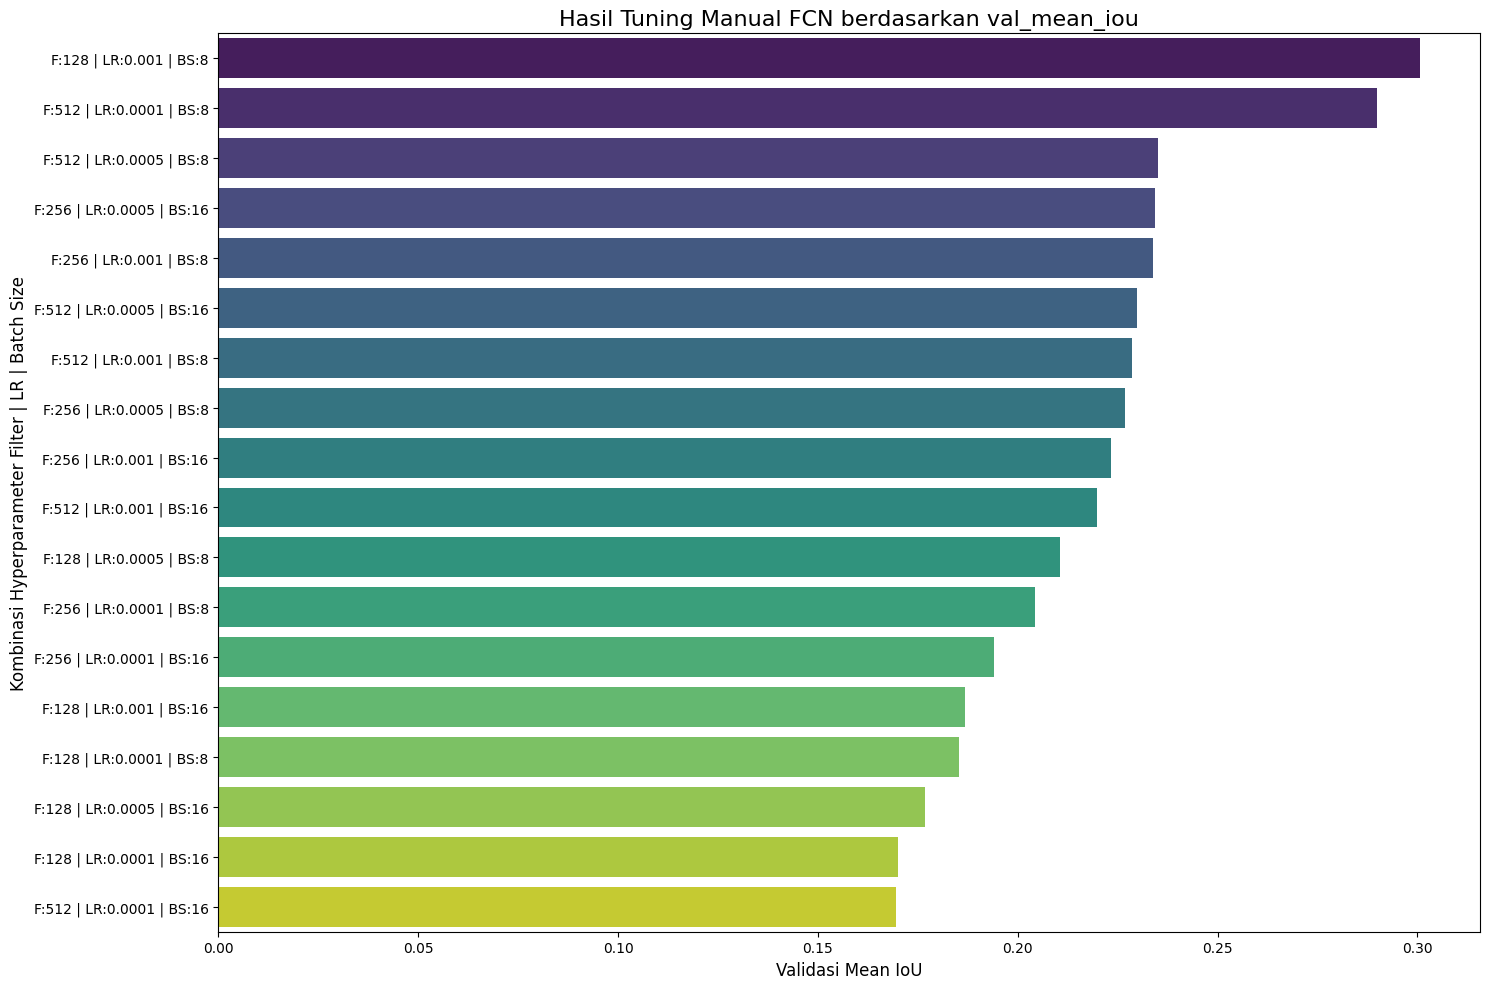

In [10]:
try:

    tuning_csv_file = "tuning_trial_fcn.csv"

    print(f"Membaca dari file '{tuning_csv_file}'")
    results_df = pd.read_csv(tuning_csv_file)

    if results_df.empty:
        print("Tidak ada data hasil untuk divisualisasikan")
    else:
        # Sortir hasil agar plot lebih rapi
        results_df_sorted = results_df.sort_values(by="val_iou", ascending=False)
        
        print("\nHasil Tuning Trial Terbaik")
        print(results_df_sorted.head())

        # PLOT 1: Plot Bar Keseluruhan
        print("\nMembuat plot val_mean_iou vs Hyperparameters")
        
        # Buat label kustom untuk sumbu Y
        results_df_sorted['hp_label'] = "F:" + results_df_sorted['filters'].astype(str) + \
                                 " | LR:" + results_df_sorted['lr'].astype(str) + \
                                 " | BS:" + results_df_sorted['batch_size'].astype(str)
        
        plt.figure(figsize=(15, 10)) 
        
        ax = sns.barplot(
            data=results_df_sorted,
            x='val_iou',
            y='hp_label',
            palette='viridis' # Gunakan palet warna
        )
        
        ax.set_title("Hasil Tuning Manual FCN berdasarkan val_mean_iou", fontsize=16)
        ax.set_xlabel("Validasi Mean IoU", fontsize=12)
        ax.set_ylabel("Kombinasi Hyperparameter Filter | LR | Batch Size", fontsize=12)
        
        plt.tight_layout()
        plt.savefig("tuning_results_plot_trial_fcn.png")
        print("Plot hasil tuning disimpan tuning_results_plot_trial_fcn.png")
        plt.show()

except FileNotFoundError:
    print(f"\nFATAL ERROR: File '{tuning_csv_file}' tidak ditemukan.")
    print("Pastikan sel sebelumnya berhasil dijalankan")
except Exception as e:
    print(f"\nGagal membuat visualisasi: {e}")


Membuat plot perbandingan detail catplot
Plot detail disimpan sebagai tuning_detail_plot_trial_fcn.png


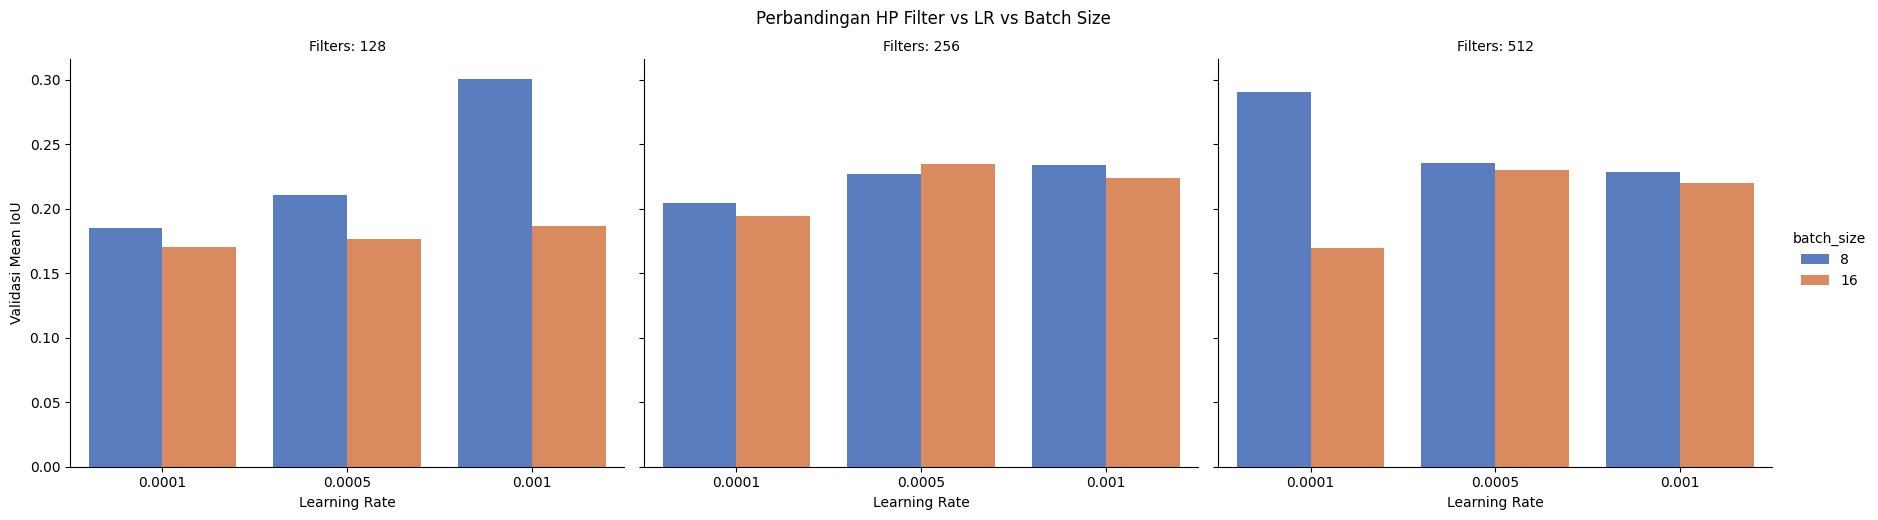

In [11]:
try:

    if 'results_df' in locals() and not results_df.empty:
        
        # PLOT 2: Plot Analisis Detail
        print("\nMembuat plot perbandingan detail catplot")
        
        g = sns.catplot(
            data=results_df,
            x='lr',           # Sumbu X: Learning Rate
            y='val_iou',      # Sumbu Y: Skor mIoU
            hue='batch_size', # Pisahkan warna berdasarkan batch size
            col='filters',    # Buat kolom terpisah untuk tiap filter
            kind='bar',       # Jenis plot: bar
            palette='muted',
            height=5,
            aspect=1.2
        )
        
        g.fig.suptitle("Perbandingan HP Filter vs LR vs Batch Size", y=1.03)
        g.set_axis_labels("Learning Rate", "Validasi Mean IoU")
        g.set_titles("Filters: {col_name}") # Judul untuk tiap kolom
        
        plt.savefig("tuning_detail_plot_trial_fcn.png")
        print("Plot detail disimpan sebagai tuning_detail_plot_trial_fcn.png")
        plt.show()
        
    else:
        print("FATAL: Variabel results_df tidak ditemukan")

except Exception as e:
    print(f"\nGagal membuat visualisasi detail: {e}")

Training Ulang Model Terbaik

In [12]:
try:
    best_batch_size = best_hps['batch_size']
    
    # Pastikan best_model
    if 'best_model' not in locals() or best_model is None:
        print("Peringatan: best_model tidak ada di memori")
        # Buat HP dari dictionary best_hps
        hp = kt.HyperParameters()
        hp.values['filters_1'] = best_hps['filters']
        hp.values['lr'] = best_hps['lr']
        best_model = build_fcn_model_for_tuner(hp)
        
except (NameError, KeyError, TypeError):
    print("FATAL: best_hps atau best_model tidak ditemukan")
    print("Pastikan Tuning berhasil berjalan")
    print("Menggunakan nilai default untuk melanjutkan")
    
    # Set default jika gagal total
    best_batch_size = 8 
    if 'best_model' not in locals() or best_model is None:
        print("Membangun model default HP terendah")
        hp = kt.HyperParameters()
        hp.values['filters_1'] = 128
        hp.values['lr'] = 1e-4
        best_model = build_fcn_model_for_tuner(hp)

train_ds_final = train_dataset.shuffle(1024).batch(best_batch_size).repeat().prefetch(AUTOTUNE)
val_ds_final = valid_dataset.batch(best_batch_size).repeat().prefetch(AUTOTUNE)

# Siapkan callback
final_model_path = "best_fcn_model.keras" 

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    final_model_path,
    save_best_only=True,
    monitor="val_mean_iou", # Monitor metrik
    mode="max", # Simpan mIoU tertinggi
    verbose=1
)

# Gunakan early stopping yang memonitor metrik yang sama
final_early_stopping_cb = keras.callbacks.EarlyStopping(
    monitor="val_mean_iou",
    mode="max",
    patience=PATIENCE_EARLYSTOP,
    restore_best_weights=True,
    verbose=1
)

# Latih Model
print(f"Melatih model terbaik dengan Batch Size = {best_batch_size}")
history = best_model.fit(
    train_ds_final,
    epochs=EPOCHS_FINAL,
    steps_per_epoch=DATASET_COUNTS["train"] // best_batch_size,
    validation_data=val_ds_final,
    validation_steps=DATASET_COUNTS["valid"] // best_batch_size,
    callbacks=[final_early_stopping_cb, checkpoint_cb]
)

print(f"\nTraining akhir selesai. Model terbaik disimpan di '{final_model_path}'")

# (Opsional) Simpan history training
history_df = pd.DataFrame(history.history)
history_df.to_csv("final_training_fcn.csv", index=False)
print("History training disimpan di 'final_training_fcn.csv'")

Melatih model terbaik dengan Batch Size = 8
Epoch 1/50
525/525 ━━━━━━━━━━━━━━━━━━━━ 0s 730ms/step - accuracy: 0.6825 - loss: 0.6237 - mean_iou: 0.2792  
Epoch 1: val_mean_iou improved from None to 0.30546, saving model to best_fcn_model.keras
525/525 ━━━━━━━━━━━━━━━━━━━━ 529s 1s/step - accuracy: 0.6806 - loss: 0.6231 - mean_iou: 0.2761 - val_accuracy: 0.6856 - val_loss: 0.6187 - val_mean_iou: 0.3055
Epoch 2/50
525/525 ━━━━━━━━━━━━━━━━━━━━ 0s 705ms/step - accuracy: 0.6758 - loss: 0.6249 - mean_iou: 0.2858  
Epoch 2: val_mean_iou improved from 0.30546 to 0.30645, saving model to best_fcn_model.keras
525/525 ━━━━━━━━━━━━━━━━━━━━ 510s 972ms/step - accuracy: 0.6805 - loss: 0.6160 - mean_iou: 0.2902 - val_accuracy: 0.6453 - val_loss: 0.6375 - val_mean_iou: 0.3064
Epoch 3/50
525/525 ━━━━━━━━━━━━━━━━━━━━ 0s 691ms/step - accuracy: 0.6847 - loss: 0.6168 - mean_iou: 0.2816  
Epoch 3: val_mean_iou did not improve from 0.30645
525/525 ━━━━━━━━━━━━━━━━━━━━ 499s 951ms/step - accuracy: 0.6782 - loss: 

Visualisasi Training Final

Visualisasi Loss

Membaca data history dari memori

Grafik Loss berhasil disimpan final_training_fcn.png


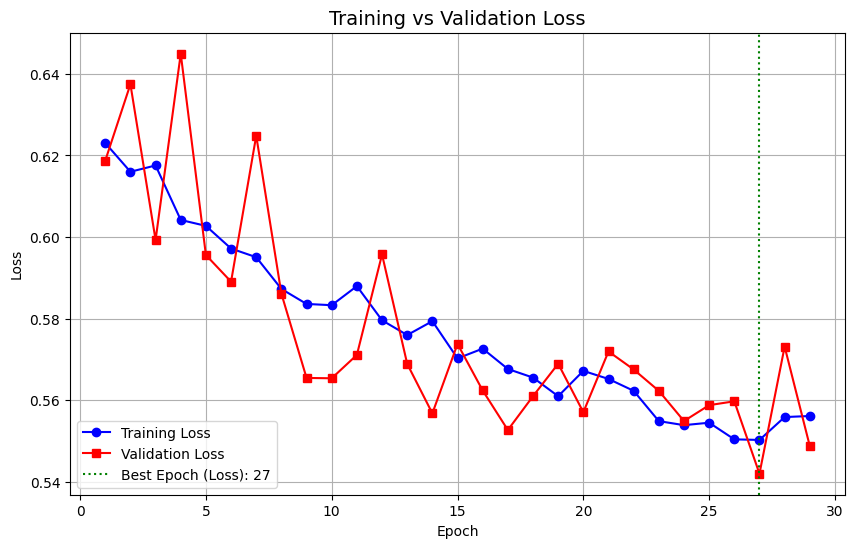

In [13]:
history_csv_path = "final_training_fcn.csv" 

try:
    # Cek apakah 'history'
    if 'history' in locals():
        history_df = pd.DataFrame(history.history)
        print("Membaca data history dari memori")
    else:
        # Jika tidak ada (misal kernel restart), baca dari CSV
        print("Objek history tidak ditemukan di memori")
        print(f"Mencoba membaca dari file '{history_csv_path}'")
        history_df = pd.read_csv(history_csv_path)

    if history_df.empty:
        print("Tidak ada data history untuk di-plot")
    else:
        # Buat variabel global untuk sel berikutnya
        num_epochs_trained = len(history_df)
        epochs = range(1, num_epochs_trained + 1)

        # PLOT 1: LOSS
        plt.figure(figsize=(10, 6)) # Ukuran untuk 1 plot
        plt.plot(epochs, history_df['loss'], 'b-o', label='Training Loss')
        plt.plot(epochs, history_df['val_loss'], 'r-s', label='Validation Loss')
        plt.title('Training vs Validation Loss', fontsize=14)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        best_epoch_loss = history_df['val_loss'].idxmin() + 1
        plt.axvline(best_epoch_loss, linestyle=':', color='g', label=f'Best Epoch (Loss): {best_epoch_loss}')
        plt.legend()
        plt.grid(True)
        
        plt.savefig('final_training_fcn.png')
        print("\nGrafik Loss berhasil disimpan final_training_fcn.png")
        plt.show()

except FileNotFoundError:
    print(f"\nFATAL ERROR: File history ('{history_csv_path}') tidak ditemukan.")
    print("Pastikan Training Ulang sudah dijalankan")
except KeyError as e:
    print(f"\nFATAL ERROR: Metrik loss atau val_loss tidak ditemukan: {e}")
except Exception as e:
    print(f"\nGagal membuat visualisasi: {e}")

Visualisasi Accuracy


Grafik Accuracy berhasil disimpan final_training_fcn_accuracy.png'


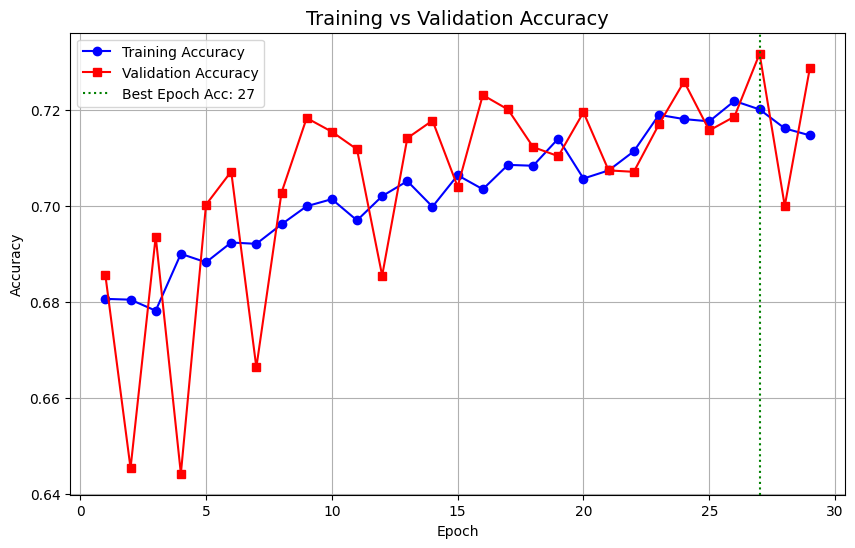

In [14]:
try:
    # PLOT 2: ACCURACY 
    plt.figure(figsize=(10, 6))
    plt.plot(epochs, history_df['accuracy'], 'b-o', label='Training Accuracy')
    plt.plot(epochs, history_df['val_accuracy'], 'r-s', label='Validation Accuracy')
    plt.title('Training vs Validation Accuracy', fontsize=14)
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    best_epoch_acc = history_df['val_accuracy'].idxmax() + 1
    plt.axvline(best_epoch_acc, linestyle=':', color='g', label=f'Best Epoch Acc: {best_epoch_acc}')
    plt.legend()
    plt.grid(True)
    
    plt.savefig('final_training_fcn_accuracy.png')
    print("\nGrafik Accuracy berhasil disimpan final_training_fcn_accuracy.png'")
    plt.show()

except NameError as e:
    print(f"\nFATAL ERROR: Variabel history_df atau epochs tidak ditemukan: {e}")
    print("Pastikan visualisasi Loss sudah dijalankan")
except KeyError as e:
    print(f"\nFATAL ERROR: Metrik accuracy atau val_accuracy tidak ditemukan: {e}")
except Exception as e:
    print(f"\nGagal membuat visualisasi: {e}")

Visualisasi mIoU


Grafik mIoU berhasil disimpan final_training_fcn_mIoU.png


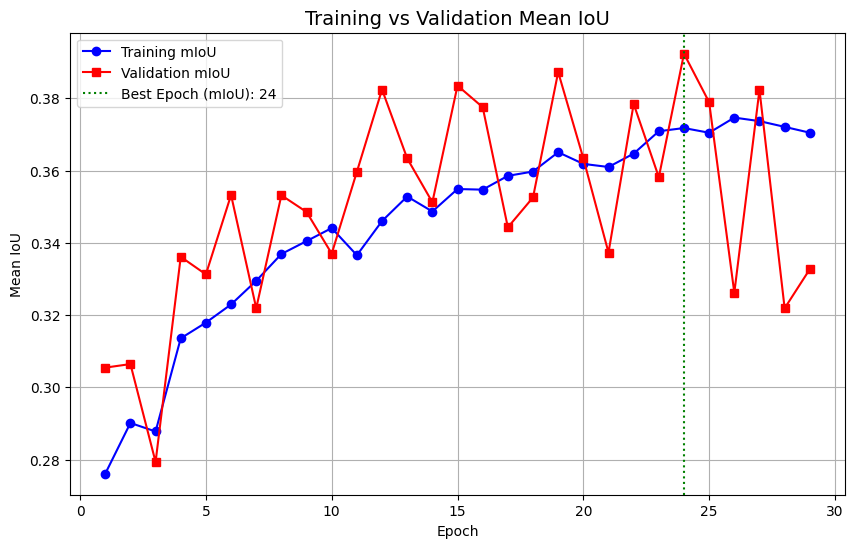

In [15]:
try:
    # PLOT 3: mIoU
    plt.figure(figsize=(10, 6))
    plt.plot(epochs, history_df['mean_iou'], 'b-o', label='Training mIoU')
    plt.plot(epochs, history_df['val_mean_iou'], 'r-s', label='Validation mIoU')
    plt.title('Training vs Validation Mean IoU', fontsize=14)
    plt.xlabel('Epoch')
    plt.ylabel('Mean IoU')
    best_epoch_iou = history_df['val_mean_iou'].idxmax() + 1
    plt.axvline(best_epoch_iou, linestyle=':', color='g', label=f'Best Epoch (mIoU): {best_epoch_iou}')
    plt.legend()
    plt.grid(True)
    
    plt.savefig('final_training_fcn_mIoU.png')
    print("\nGrafik mIoU berhasil disimpan final_training_fcn_mIoU.png")
    plt.show()

except NameError as e:
    print(f"\nFATAL ERROR: Variabel history_df atau epochs tidak ditemukan: {e}")
    print("Pastikanvisualisasi Loss sudah dijalankan")
except KeyError as e:
    print(f"\nFATAL ERROR: Metrik mean_iou atau val_mean_iou tidak ditemukan: {e}")
    print("Pastikan metrik model.compile sudah benar")
except Exception as e:
    print(f"\nGagal membuat visualisasi: {e}")

Visualisasi Arsitektur Model Final

In [16]:
try:
    if 'best_model' not in locals() or best_model is None:
        print(f"Memuat model final dari file: {final_model_path}")

        best_model = keras.models.load_model(
            final_model_path, 
            custom_objects={'SparseMeanIoU': SparseMeanIoU}
        )
        print("Model berhasil dimuat")
        
except NameError as e:
    print(f"FATAL: Variabel tidak ditemukan: {e}")
    print("Pastikan Definisi SparseMeanIoU final_model_path sudah dijalankan")
    
except Exception as e:
    print(f"FATAL: Gagal memuat model. Jalankan ulang Error: {e}")


# Cetak Visualisasi Tabel (Summary)
if 'best_model' in locals() and best_model is not None:
    print("\nModel Summary Final Terbaik")
    best_model.summary(line_length=120)
    
    # Simpan Visualisasi Gambar (Diagram)
    final_plot_path = "fcn_architecture_final.png"
    try:
        tf.keras.utils.plot_model(
            best_model,
            to_file=final_plot_path,
            show_shapes=True,
            show_layer_names=True,
            dpi=70 
        )
        print(f"\nDiagram arsitektur model final disimpan sebagai '{final_plot_path}'")
    except Exception as e:
        print(f"Gagal menyimpan plot model: {e}")
else:
    print("Tidak ada model terbaik untuk divisualisasikan")


Model Summary Final Terbaik


Model: "FCN_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                      ┃ Output Shape                 ┃           Param # ┃ Connected to              
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━
│ input_layer_1 (InputLayer)        │ (None, 256, 256, 3)          │                 0 │ -                         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv1_pad (ZeroPadding2D)         │ (None, 262, 262, 3)          │                 0 │ input_layer_1[0][0]       
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv1_conv (Conv2D)               │ (None, 128, 128, 64)         │             9,472 │ conv1_pad[0][0]           
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv1_bn (BatchNormalization)     │ (None, 128, 128, 64)         │               256 │ conv1_conv[0][0]          
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv1_relu (Activation)           │ (None, 128, 128, 64)         │                 0 │ conv1_bn[0][0]            
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ pool1_pad (ZeroPadding2D)         │ (None, 130, 130, 64)         │                 0 │ conv1_relu[0][0]          
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ pool1_pool (MaxPooling2D)         │ (None, 64, 64, 64)           │                 0 │ pool1_pad[0][0]           
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_1_conv (Conv2D)      │ (None, 64, 64, 64)           │             4,160 │ pool1_pool[0][0]          
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_1_bn                 │ (None, 64, 64, 64)           │               256 │ conv2_block1_1_conv[0][0] 
│ (BatchNormalization)              │                              │                   │                           
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_1_relu (Activation)  │ (None, 64, 64, 64)           │                 0 │ conv2_block1_1_bn[0][0]   
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_2_conv (Conv2D)      │ (None, 64, 64, 64)           │            36,928 │ conv2_block1_1_relu[0][0] 
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_2_bn                 │ (None, 64, 64, 64)           │               256 │ conv2_block1_2_conv[0][0] 
│ (BatchNormalization)              │                              │                   │                           
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_2_relu (Activation)  │ (None, 64, 64, 64)           │                 0 │ conv2_block1_2_bn[0][0]   
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_0_conv (Conv2D)      │ (None, 64, 64, 256)          │            16,640 │ pool1_pool[0][0]          
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ conv2_block1_3_conv (Conv2D)      │ (None, 64, 64, 256)          │            16,640 │ conv2_block1_2_relu[0][0] 
├───────────────────────────────────┼───────────────────

 Total params: 37,185,814 (141.85 MB)

 Trainable params: 4,532,700 (17.29 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 9,065,402 (34.58 MB)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.

Diagram arsitektur model final disimpan sebagai 'fcn_architecture_final.png'


Model & Evaluasi

In [17]:
final_model_path = "best_fcn_model.keras" 

# Muat model
try:
    if 'best_model' not in locals() or best_model is None:
        print(f"Memuat model final dari file: {final_model_path}")
        best_model = keras.models.load_model(
            final_model_path, 
            custom_objects={'SparseMeanIoU': SparseMeanIoU}
        )
    print("Model terbaik siap untuk evaluasi")
except NameError as e:
    print(f"FATAL: Variabel tidak ditemukan: {e}")
except Exception as e:
    print(f"FATAL: Gagal memuat model dari '{final_model_path}'. Error: {e}")

# Siapkan Test Set
try:
    test_batch_size = best_hps.get('batch_size', 8)
except NameError:
    print("Peringatan: best_hps tidak ditemukan, menggunakan batch_size default=8")
    test_batch_size = 8

test_ds_final = test_dataset.batch(test_batch_size).repeat().prefetch(AUTOTUNE)
test_steps = DATASET_COUNTS["test"] // test_batch_size

eval_results = [0, 0, 0] # Placeholder

if 'best_model' in locals() and test_steps > 0:
    print(f"Mengevaluasi {DATASET_COUNTS['test']} gambar test (steps={test_steps})")

    # Evaluasi 
    try:
        eval_results = best_model.evaluate(
            test_ds_final, 
            steps=test_steps,
            verbose=1
        )
        print("\nHasil Model Evaluate")
        print(f"Test Loss    : {eval_results[0]:.4f}")
        print(f"Test Accuracy: {eval_results[1]:.4f}")
        print(f"Test mIoU    : {eval_results[2]:.4f}")
    except Exception as e:
        print(f"Gagal 'model.evaluate': {e}")
        
elif test_steps == 0:
    print(f"FATAL: Batch size ({test_batch_size}) terlalu besar untuk data test ({DATASET_COUNTS['test']})")
else:
    print("Model tidak ditemukan. Evaluasi dibatalkan.")

Model terbaik siap untuk evaluasi
Mengevaluasi 90 gambar test (steps=11)
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 979ms/step - accuracy: 0.7338 - loss: 0.5323 - mean_iou: 0.4372

Hasil Model Evaluate
Test Loss    : 0.5323
Test Accuracy: 0.7338
Test mIoU    : 0.4372


Evaluasi Mendalam Pengumpulan Piksel

In [18]:
if 'best_model' in locals() and test_steps > 0:
    print("Menghitung prediksi piksel")
    all_y_true_sparse = []
    all_y_pred_sparse = []
    
    # Iterasi batch-per-batch di test set
    for images, masks_sparse in test_ds_final.take(test_steps):
        # 'masks_sparse' adalah (B, H, W) - int [0,1,2,3]
        
        preds_softmax = best_model.predict(images, verbose=0)
        # 'preds_sparse' adalah (B, H, W) - int [0,1,2,3]
        preds_sparse = np.argmax(preds_softmax, axis=-1)
        
        # Kumpulkan untuk metrik sklearn (flatten)
        all_y_true_sparse.extend(masks_sparse.numpy().ravel())
        all_y_pred_sparse.extend(preds_sparse.ravel())

    all_y_true = np.array(all_y_true_sparse)
    all_y_pred = np.array(all_y_pred_sparse)
    print("Perhitungan piksel selesai")
    
else:
    print("Model tidak ditemukan atau test_steps=0. Evaluasi dibatalkan")

Menghitung prediksi piksel
Perhitungan piksel selesai


Classification Report & Confusion Matrix


Metrik Sklearn Macro Avg
Precision (Macro Avg)  : 0.6174
Recall (Macro Avg)     : 0.5404
F1-Score (Macro Avg)   : 0.5350
Accuracy: 0.8719

Classification Report
              precision    recall  f1-score   support

 Retak-Berat       0.77      0.37      0.50    133865
Retak-Ringan       0.52      0.33      0.40     36785
 Tidak-Retak       0.57      0.92      0.70   1818410

   micro avg       0.57      0.87      0.69   1989060
   macro avg       0.62      0.54      0.54   1989060
weighted avg       0.58      0.87      0.68   1989060


Confusion Matrix


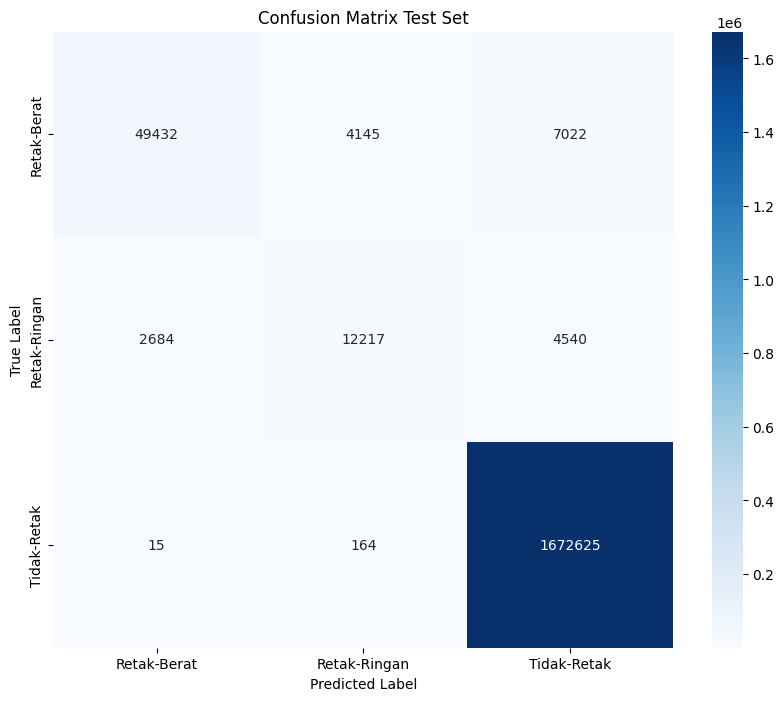

In [22]:
from sklearn.metrics import (
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    classification_report, 
    accuracy_score
)

try:
    if 'all_y_true' in locals() and len(all_y_true) > 0:

        labels_to_include = list(range(1, NUM_CLASSES))
        target_names_to_include = CLASS_NAMES[1:]    

        print("\nMetrik Sklearn Macro Avg")

        precision = precision_score(all_y_true, all_y_pred, labels=labels_to_include, average='macro', zero_division=0)
        recall = recall_score(all_y_true, all_y_pred, labels=labels_to_include, average='macro', zero_division=0)
        f1 = f1_score(all_y_true, all_y_pred, labels=labels_to_include, average='macro', zero_division=0)

        print(f"Precision (Macro Avg)  : {precision:.4f}")
        print(f"Recall (Macro Avg)     : {recall:.4f}")
        print(f"F1-Score (Macro Avg)   : {f1:.4f}")

        try:

            interest_mask = (all_y_true > 0)
            y_true_3_classes = all_y_true[interest_mask]
            y_pred_3_classes = all_y_pred[interest_mask]

            accuracy_3_classes = accuracy_score(y_true_3_classes, y_pred_3_classes)
            print(f"Accuracy: {accuracy_3_classes:.4f}")
        except Exception as e:
            print(f"Tidak dapat menghitung akurasi: {e}")

        print("\nClassification Report")
        
        print(classification_report(
            all_y_true, 
            all_y_pred, 
            labels=labels_to_include, 
            target_names=target_names_to_include,
            zero_division=0
        ))

        print("\nConfusion Matrix")

        cm_3_classes = confusion_matrix(all_y_true, all_y_pred, labels=labels_to_include) 

        plt.figure(figsize=(10, 8)) 
        
        sns.heatmap(cm_3_classes, annot=True, fmt='d', cmap='Blues', 
                    xticklabels=target_names_to_include, 
                    yticklabels=target_names_to_include)
        
        plt.title('Confusion Matrix Test Set')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')
        plt.savefig("confusion_matrix_fcn.png")
        plt.show()

    else:
        print("FATAL: Variabel 'all_y_true' tidak ditemukan.")
        print("Pastikan Pengumpulan Pikselsudah dijalankan.")

except NameError as e:
    print(f"\nFATAL ERROR: Variabel tidak ditemukan: {e}")
    print("Pastikan CLASS_NAMES dan all_y_true sudah dijalankan.")
except Exception as e:
    print(f"\nGagal membuat metrik Sklearn: {e}")

Visualisasi Hasil Prediksi

In [24]:
OUTPUT_VIS_DIR = "hasil_prediksi_visual"
os.makedirs(OUTPUT_VIS_DIR, exist_ok=True)
print(f"Hasil akan disimpan di folder: {OUTPUT_VIS_DIR}")

try:

    final_model_path = "best_fcn_model.keras" 

    # Muat model
    if 'best_model' not in locals() or best_model is None:
        print(f"Memuat model final dari file: {final_model_path}")
        best_model = keras.models.load_model(
            final_model_path, 
            custom_objects={'SparseMeanIoU': SparseMeanIoU}
        )
        print("Model berhasil dimuat")
        
    # Pastikan test_ds_final
    if 'test_ds_final' not in locals() or 'test_steps' not in locals():
        print("FATAL: 'test_ds_final' atau 'test_steps' tidak ditemukan")
        print("Jalankan Evaluasi Cepat terlebih dahulu")
        raise NameError("'test_ds_final' or 'test_steps' not defined")

    custom_colors_hex = [
        '#000000', # Index 0: Background (Hitam)
        '#FF0000', # Index 1: Retak-Berat (MERAH)
        '#00FF00', # Index 2: Retak-Ringan (HIJAU)
        '#0000FF', # Index 3: Tidak-Retak (BIRU)
    ]
    
    available_colors = custom_colors_hex + ['#FFFF00', '#FF00FF', '#00FFFF']
    final_colors = available_colors[:NUM_CLASSES] # Ambil 4 warna pertama

    custom_cmap = ListedColormap(final_colors)
    boundaries = np.arange(NUM_CLASSES + 1) - 0.5
    custom_norm = BoundaryNorm(boundaries, custom_cmap.N)
    
    # Loop melalui SEMUA BATCH di test set
    print(f"Memproses {test_steps} batch dari test set")
    total_images_saved = 0

    for i, (images, masks_sparse) in enumerate(test_ds_final.take(test_steps)):
        
        print(f"Memproses Batch {i+1}/{test_steps}")
        
        softmax_preds = best_model.predict(images, verbose=0)
        preds_sparse = np.argmax(softmax_preds, axis=-1) 
        masks_sparse_np = masks_sparse.numpy()

        # Loop melalui SETIAP GAMBAR di dalam batch
        for j in range(len(images)):
            
            img = images[j]
            mask_gt = masks_sparse_np[j]
            mask_pred = preds_sparse[j]
            
            fig, axes = plt.subplots(1, 3, figsize=(15, 6)) # 1 baris, 3 kolom
            
            # Plot Input Image
            axes[0].imshow(img)
            axes[0].set_title("Input Image")
            axes[0].axis("on")

            # Plot Ground Truth Mask
            axes[1].imshow(mask_gt, cmap=custom_cmap, norm=custom_norm)
            axes[1].set_title("Ground Truth Label Asli")
            axes[1].axis("on")

            # Plot Predicted Mask
            im = axes[2].imshow(mask_pred, cmap=custom_cmap, norm=custom_norm)
            axes[2].set_title("Hasil Prediksi Model")
            axes[2].axis("on") 
                
            # Tambahkan Colorbar
            plt.tight_layout(rect=[0, 0, 0.9, 1]) 
            cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7]) 
            cbar = fig.colorbar(im, cax=cbar_ax, ticks=np.arange(NUM_CLASSES))
            cbar.ax.set_yticklabels(CLASS_NAMES) # Dari Cell 3
            
            # Simpan ke file unik di folder output
            file_name = f"hasil_prediksi_batch_{i}_img_{j}.png"
            save_path = os.path.join(OUTPUT_VIS_DIR, file_name)
            plt.savefig(save_path, dpi=100)
            
            # Tutup figure agar memori tidak penuh
            plt.close(fig)
            total_images_saved += 1

    print(f"\nVisualisasi Selesai. {total_images_saved} gambar telah disimpan di folder '{OUTPUT_VIS_DIR}'")

except NameError as e:
    print(f"\nFATAL ERROR: Variabel penting tidak ditemukan: {e}")
except Exception as e:
    print(f"Terjadi error saat visualisasi: {e}")

Hasil akan disimpan di folder: hasil_prediksi_visual
Memproses 11 batch dari test set
Memproses Batch 1/11
Memproses Batch 2/11
Memproses Batch 3/11
Memproses Batch 4/11
Memproses Batch 5/11
Memproses Batch 6/11
Memproses Batch 7/11
Memproses Batch 8/11
Memproses Batch 9/11
Memproses Batch 10/11
Memproses Batch 11/11

Visualisasi Selesai. 88 gambar telah disimpan di folder 'hasil_prediksi_visual'


Visualisasi Sampel Prediksi

Menampilkan 8 sampel prediksi


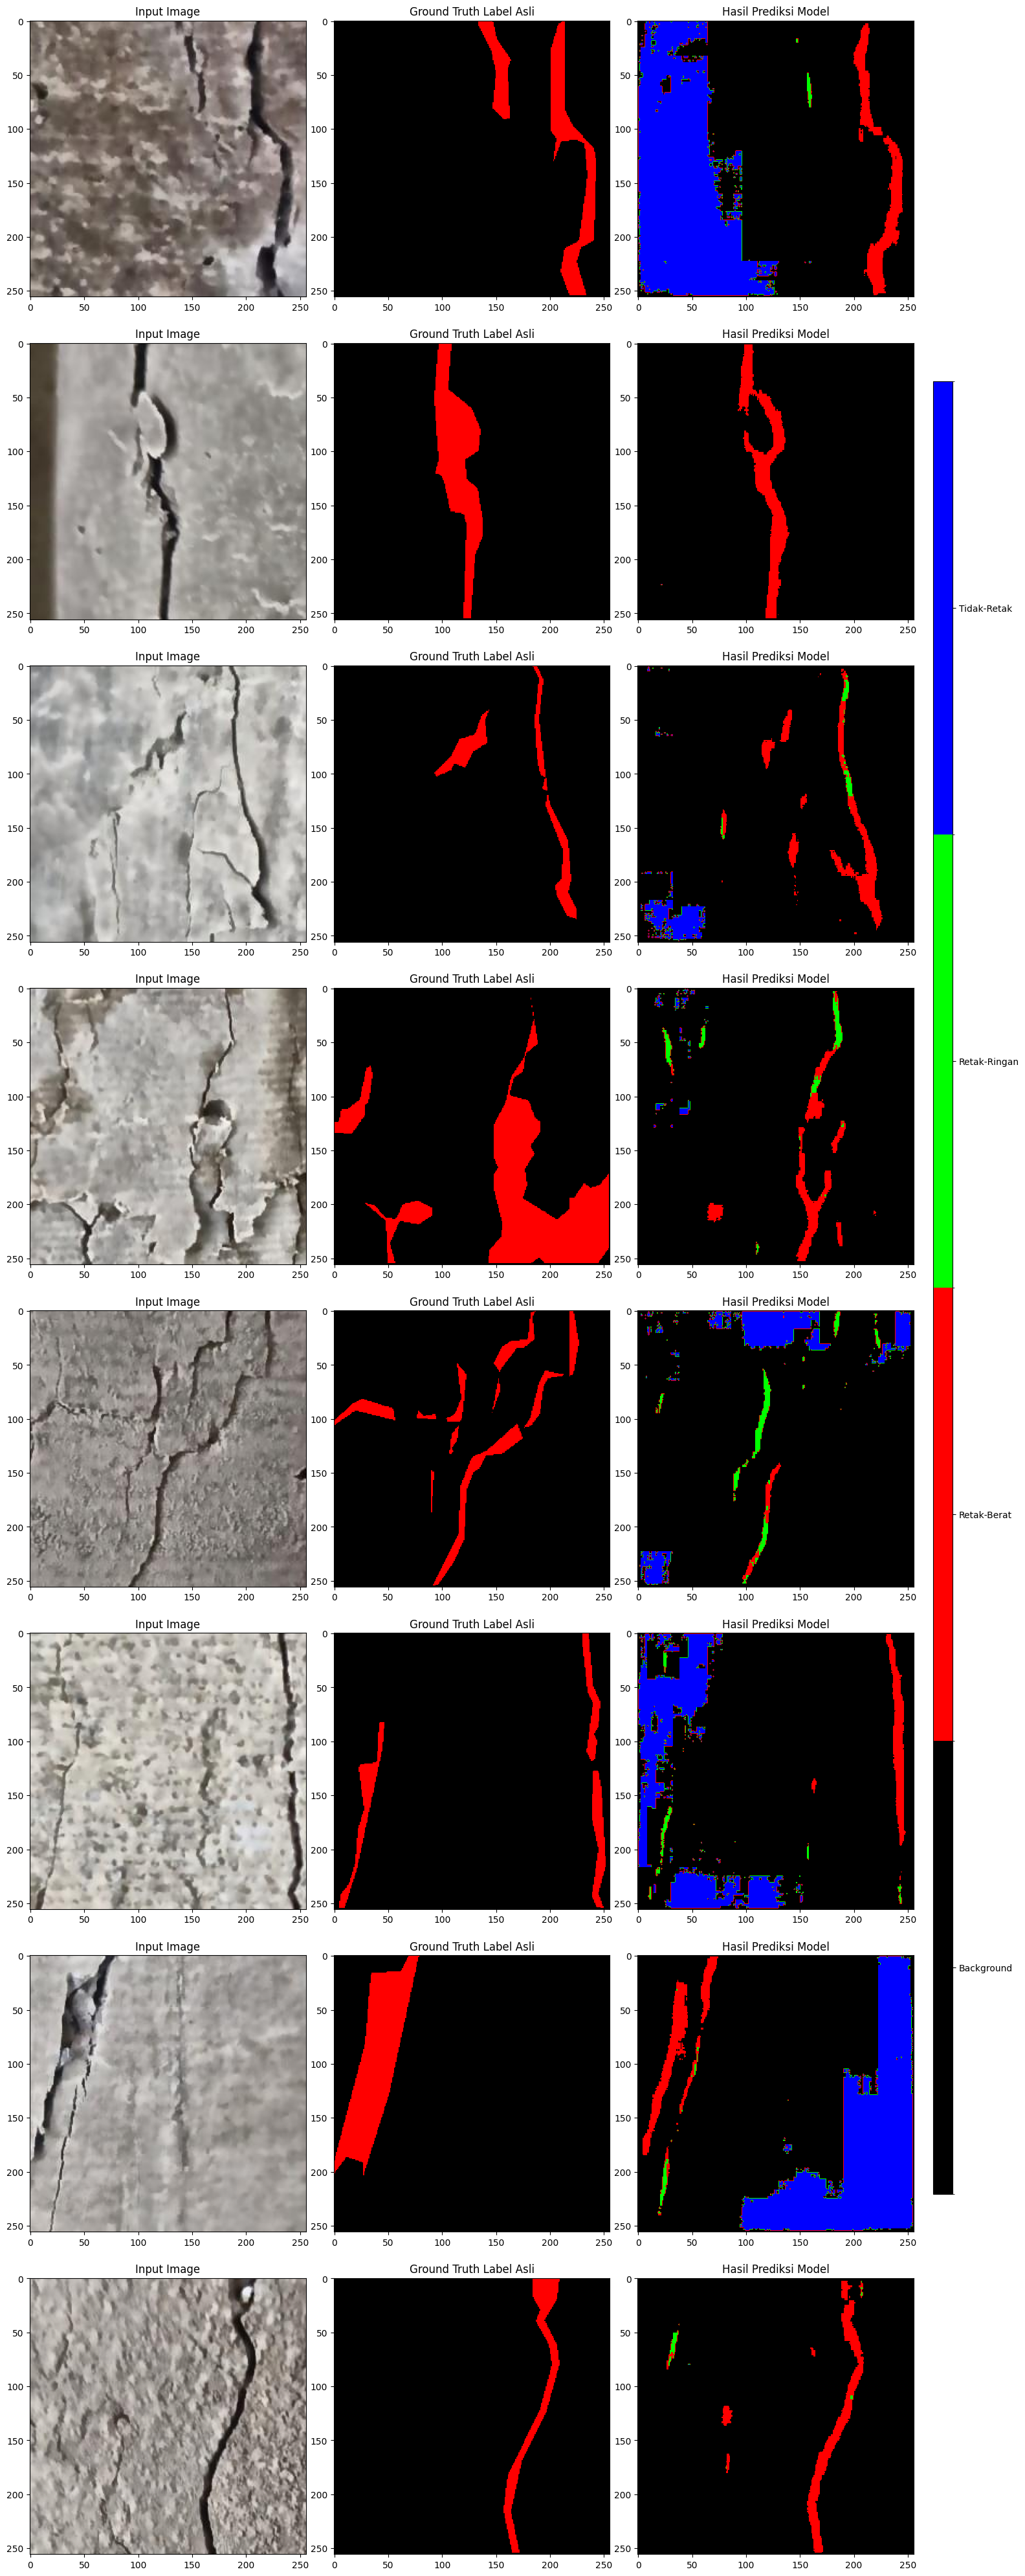

In [25]:
try:

    if 'best_model' not in locals() or best_model is None:
        print("Model tidak ditemukan. Memuat ulang")
        final_model_path = "best_fcn_model.keras"
        best_model = keras.models.load_model(
            final_model_path, 
            custom_objects={'SparseMeanIoU': SparseMeanIoU} 
        )
    
    if 'test_ds_final' not in locals():
        print("FATAL: test_ds_final tidak ditemukan")
        raise NameError("test_ds_final not defined")

    custom_colors_hex = [
        '#000000', # Index 0: Background (Hitam)
        '#FF0000', # Index 1: Retak-Berat (MERAH)
        '#00FF00', # Index 2: Retak-Ringan (HIJAU)
        '#0000FF', # Index 3: Tidak-Retak (BIRU)
    ]
    
    available_colors = custom_colors_hex + ['#FFFF00', '#FF00FF', '#00FFFF']
    final_colors = available_colors[:NUM_CLASSES] # Ambil 4 warna pertama
    
    custom_cmap = ListedColormap(final_colors)
    boundaries = np.arange(NUM_CLASSES + 1) - 0.5
    custom_norm = BoundaryNorm(boundaries, custom_cmap.N)
    
    # Ambil HANYA SATU BATCH untuk ditampilkan
    for images, masks_sparse in test_ds_final.take(1):
        
        softmax_preds = best_model.predict(images, verbose=0)
        preds_sparse = np.argmax(softmax_preds, axis=-1) 
        masks_sparse_np = masks_sparse.numpy()

        # Tampilkan seisi batch
        num_images_to_show = len(images)
        
        fig, axes = plt.subplots(num_images_to_show, 3, figsize=(15, 5 * num_images_to_show))
        
        if num_images_to_show == 1:
            axes = np.array([axes]) # Sesuaikan jika batch_size=1

        print(f"Menampilkan {num_images_to_show} sampel prediksi")
        for i in range(num_images_to_show):
            axes[i, 0].imshow(images[i])
            axes[i, 0].set_title("Input Image")
            axes[i, 0].axis("on")

            axes[i, 1].imshow(masks_sparse_np[i], cmap=custom_cmap, norm=custom_norm)
            axes[i, 1].set_title("Ground Truth Label Asli")
            axes[i, 1].axis("on")

            im = axes[i, 2].imshow(preds_sparse[i], cmap=custom_cmap, norm=custom_norm)
            axes[i, 2].set_title("Hasil Prediksi Model")
            axes[i, 2].axis("on")
            
        # Tambahkan Colorbar
        plt.tight_layout(rect=[0, 0, 0.95, 1]) 
        cbar_ax = fig.add_axes([0.96, 0.15, 0.02, 0.7]) 
        cbar = fig.colorbar(im, cax=cbar_ax, ticks=np.arange(NUM_CLASSES))
        cbar.ax.set_yticklabels(CLASS_NAMES)
        
        # Tampilkan plot di notebook
        plt.show()

except NameError as e:
    print(f"\nFATAL ERROR: Variabel penting tidak ditemukan: {e}")
except Exception as e:
    print(f"Terjadi error saat visualisasi: {e}")

Model Inference

In [29]:
MODEL_FILE = "best_fcn_model.keras"
MODEL_INPUT_SIZE = (IMG_HEIGHT, IMG_WIDTH) # (H, W)

# Muat Model Terlatih
try:
    # Muat model
    model = tf.keras.models.load_model(
        MODEL_FILE, 
        custom_objects={'SparseMeanIoU': SparseMeanIoU} # Dari Cell 7
    )
    print(f"\nModel '{MODEL_FILE}' berhasil dimuat")
    
except NameError as e:
    print(f"FATAL: Variabel SparseMeanIoU tidak ditemukan: {e}")
    print("Pastikan Cell 7 sudah dijalankan terlebih dahulu.")
except Exception as e:
    print(f"\nGAGAL memuat model: {e}")
    print(f"Pastikan file '{MODEL_FILE}' ada di direktori yang sama.")


# Verifikasi Variabel Konfigurasi
try:
    print("\nVerifikasi Konfigurasi")
    print(f"Ukuran Input Model (H, W): {MODEL_INPUT_SIZE}")
    print(f"Jumlah Kelas (NUM_CLASSES): {NUM_CLASSES}")
    print(f"Nama Kelas: {CLASS_NAMES}")
    
    # Cek logika sederhana (pastikan 4 kelas)
    if NUM_CLASSES != 4 or len(CLASS_NAMES) != NUM_CLASSES:
        print(f"PERINGATAN: Konfigurasi kelas mungkin tidak sinkron!")
    else:
        print("Konfigurasi inferensi selesai")
        
except NameError as e:
    print(f"\nFATAL: Variabel konfigurasi (seperti NUM_CLASSES) tidak ditemukan: {e}.")
    print("Pastikan Cell 2 & 3 sudah dijalankan.")


Model 'best_fcn_model.keras' berhasil dimuat

Verifikasi Konfigurasi
Ukuran Input Model (H, W): (256, 256)
Jumlah Kelas (NUM_CLASSES): 4
Nama Kelas: ['Background', 'Retak-Berat', 'Retak-Ringan', 'Tidak-Retak']
Konfigurasi inferensi selesai


Fungsi Bantuan & Palet Warna (RGB)

In [30]:
try:
    # Verifikasi Konfigurasi
    if NUM_CLASSES != 4 or len(CLASS_NAMES) != 4:
        print(f"PERINGATAN: Konfigurasi tidak cocok! NUM_CLASSES={NUM_CLASSES} / CLASS_NAMES={len(CLASS_NAMES)}")
    
    COLOR_MAP_BGR = np.zeros((NUM_CLASSES, 3), dtype=np.uint8)
    COLOR_MAP_BGR[0] = [0, 0, 0]     # 0: Background -> Hitam
    COLOR_MAP_BGR[1] = [0, 0, 255]   # 1: Retak-Berat -> (MERAH)
    COLOR_MAP_BGR[2] = [0, 255, 0]   # 2: Retak-Ringan -> (HIJAU)
    COLOR_MAP_BGR[3] = [255, 0, 0]   # 3: Tidak-Retak -> (BIRU)
    
    print("\nPalet warna COLOR_MAP_BGR:")
    print(f"  Label 0 ({CLASS_NAMES[0]}): {COLOR_MAP_BGR[0]} (Hitam)")
    print(f"  Label 1 ({CLASS_NAMES[1]}): {COLOR_MAP_BGR[1]} (Merah)")
    print(f"  Label 2 ({CLASS_NAMES[2]}): {COLOR_MAP_BGR[2]} (Hijau)")
    print(f"  Label 3 ({CLASS_NAMES[3]}): {COLOR_MAP_BGR[3]} (Biru)")
        
except NameError as e:
    print(f"FATAL ERROR: Variabel tidak ditemukan ({e})")
    # Fallback jika terjadi error
    COLOR_MAP_BGR = np.array([[0,0,0], [0,0,255], [0,255,0], [255,0,0]], dtype=np.uint8)

def mask_to_bgr(mask, color_map):
    """Mengubah mask 2D (HxW) menjadi gambar BGR (HxWx3) berdasarkan palet warna"""
    mask = mask.astype(np.int32)
    # Indexing numpy akan memetakan setiap nilai di 'mask' ke 'color_map'
    bgr_mask = color_map[mask]
    return bgr_mask


Palet warna COLOR_MAP_BGR:
  Label 0 (Background): [0 0 0] (Hitam)
  Label 1 (Retak-Berat): [  0   0 255] (Merah)
  Label 2 (Retak-Ringan): [  0 255   0] (Hijau)
  Label 3 (Tidak-Retak): [255   0   0] (Biru)


Inference Otomatis (Simpan Hasil Overlay)

In [31]:
try:
    INPUT_DIR = "Tanggul/eksperimen/dataset/images" 
    OUTPUT_DIR = "results_segmentation_fcn" 
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    # Ukuran Input Model (W, H) untuk cv2.resize
    MODEL_INPUT_SIZE_CV2 = (IMG_WIDTH, IMG_HEIGHT) 
    
    print(f"Mencari gambar di folder input: {INPUT_DIR}")
    
    # Cari Semua File Gambar
    image_paths = glob.glob(os.path.join(INPUT_DIR, "*.jpg")) + \
                  glob.glob(os.path.join(INPUT_DIR, "*.jpeg")) + \
                  glob.glob(os.path.join(INPUT_DIR, "*.png"))
    image_paths.sort()
    JUMLAH_GAMBAR = len(image_paths)
    
    if JUMLAH_GAMBAR == 0:
        print(f"Tidak ada gambar .jpg atau .png yang ditemukan di {INPUT_DIR}")
    else:
        print(f"Ditemukan {JUMLAH_GAMBAR} file gambar. Hasil akan disimpan di {OUTPUT_DIR}")

    # Loop dan Proses Setiap Gambar
    for i, image_path in enumerate(image_paths):
        base_filename = os.path.basename(image_path)
        print(f"  Memproses gambar {i+1}/{JUMLAH_GAMBAR}: {base_filename}", end="")
        
        try:
            # Muat gambar ASLI (dalam BGR)
            img_bgr = cv2.imread(image_path)
            if img_bgr is None:
                print("Gagal memuat, dilewati")
                continue
            original_shape = img_bgr.shape[:2] # (height, width)

            # Pre-process (Model dilatih pada RGB)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            # Resize ke ukuran input model (W, H)
            img_resized = cv2.resize(img_rgb, MODEL_INPUT_SIZE_CV2, interpolation=cv2.INTER_LINEAR)
            img_input = img_resized.astype(np.float32) / 255.0
            img_input = np.expand_dims(img_input, axis=0) # (1, H, W, 3)

            # Prediksi model
            softmax_preds = model.predict(img_input, verbose=0)
            pred_mask = np.argmax(softmax_preds[0], axis=-1) # (H, W)

            # Post-process Ubah mask ke BGR
            pred_mask_bgr = mask_to_bgr(pred_mask, COLOR_MAP_BGR) 
            
            # Resize mask ke ukuran asli
            pred_mask_resized_bgr = cv2.resize(
                pred_mask_bgr, 
                (original_shape[1], original_shape[0]), # (W, H)
                interpolation=cv2.INTER_NEAREST
            )

            # Buat overlay (BGR + BGR)
            overlay_bgr = cv2.addWeighted(img_bgr, 0.6, pred_mask_resized_bgr, 0.4, 0)

            # Simpan Hasil (dalam format BGR)
            output_filename = f"hasil_segmentasi_{base_filename}" 
            output_path = os.path.join(OUTPUT_DIR, output_filename)
            
            cv2.imwrite(output_path, overlay_bgr)
            print("Selesai")
            
        except Exception as e:
            print(f"Gagal. Error: {e}")

    print(f"\nInference otomatis selesai{JUMLAH_GAMBAR} gambar telah diproses")
    print(f"Hasil disimpan di folder: {OUTPUT_DIR}")

except NameError as ne:
    print(f"\nFATAL: Variabel tidak ditemukan: {ne}")
    print("Pastikan model dan mask_to_bgr, COLOR_MAP_BGR dijalankan")
except Exception as ex:
    print(f"\nTerjadi error: {ex}")

Mencari gambar di folder input: Tanggul/eksperimen/dataset/images
Ditemukan 405 file gambar. Hasil akan disimpan di results_segmentation_fcn
Selesaioses gambar 1/405: 001.jpg
Selesaioses gambar 2/405: 002.jpg
Selesaioses gambar 3/405: 003.jpg
Selesaioses gambar 4/405: 004.jpg
Selesaioses gambar 5/405: 005-101.jpg
Selesaioses gambar 6/405: 005-136.jpg
Selesaioses gambar 7/405: 005-171.jpg
Selesaioses gambar 8/405: 005-189.jpg
Selesaioses gambar 9/405: 005-206.jpg
Selesaioses gambar 10/405: 005-31.jpg
Selesaioses gambar 11/405: 005-83.jpg
Selesaioses gambar 12/405: 005.jpg
Selesaioses gambar 13/405: 006-104.jpg
Selesaioses gambar 14/405: 006-105.jpg
Selesaioses gambar 15/405: 006-120.jpg
Selesaioses gambar 16/405: 006-136.jpg
Selesaioses gambar 17/405: 006-153.jpg
Selesaioses gambar 18/405: 006-169.jpg
Selesaioses gambar 19/405: 006-185.jpg
Selesaioses gambar 20/405: 006-202.jpg
Selesaioses gambar 21/405: 006-219.jpg
  Memproses gambar 22/405: 006-88.jpgSelesai
Selesaioses gambar 23/405:

Visualisasi Sampel Hasil Inference

Memuat hasil gambar dari folder 'results_segmentation_fcn' untuk ditampilkan...
Ditemukan 405 hasil. Menampilkan 9 gambar pertama.


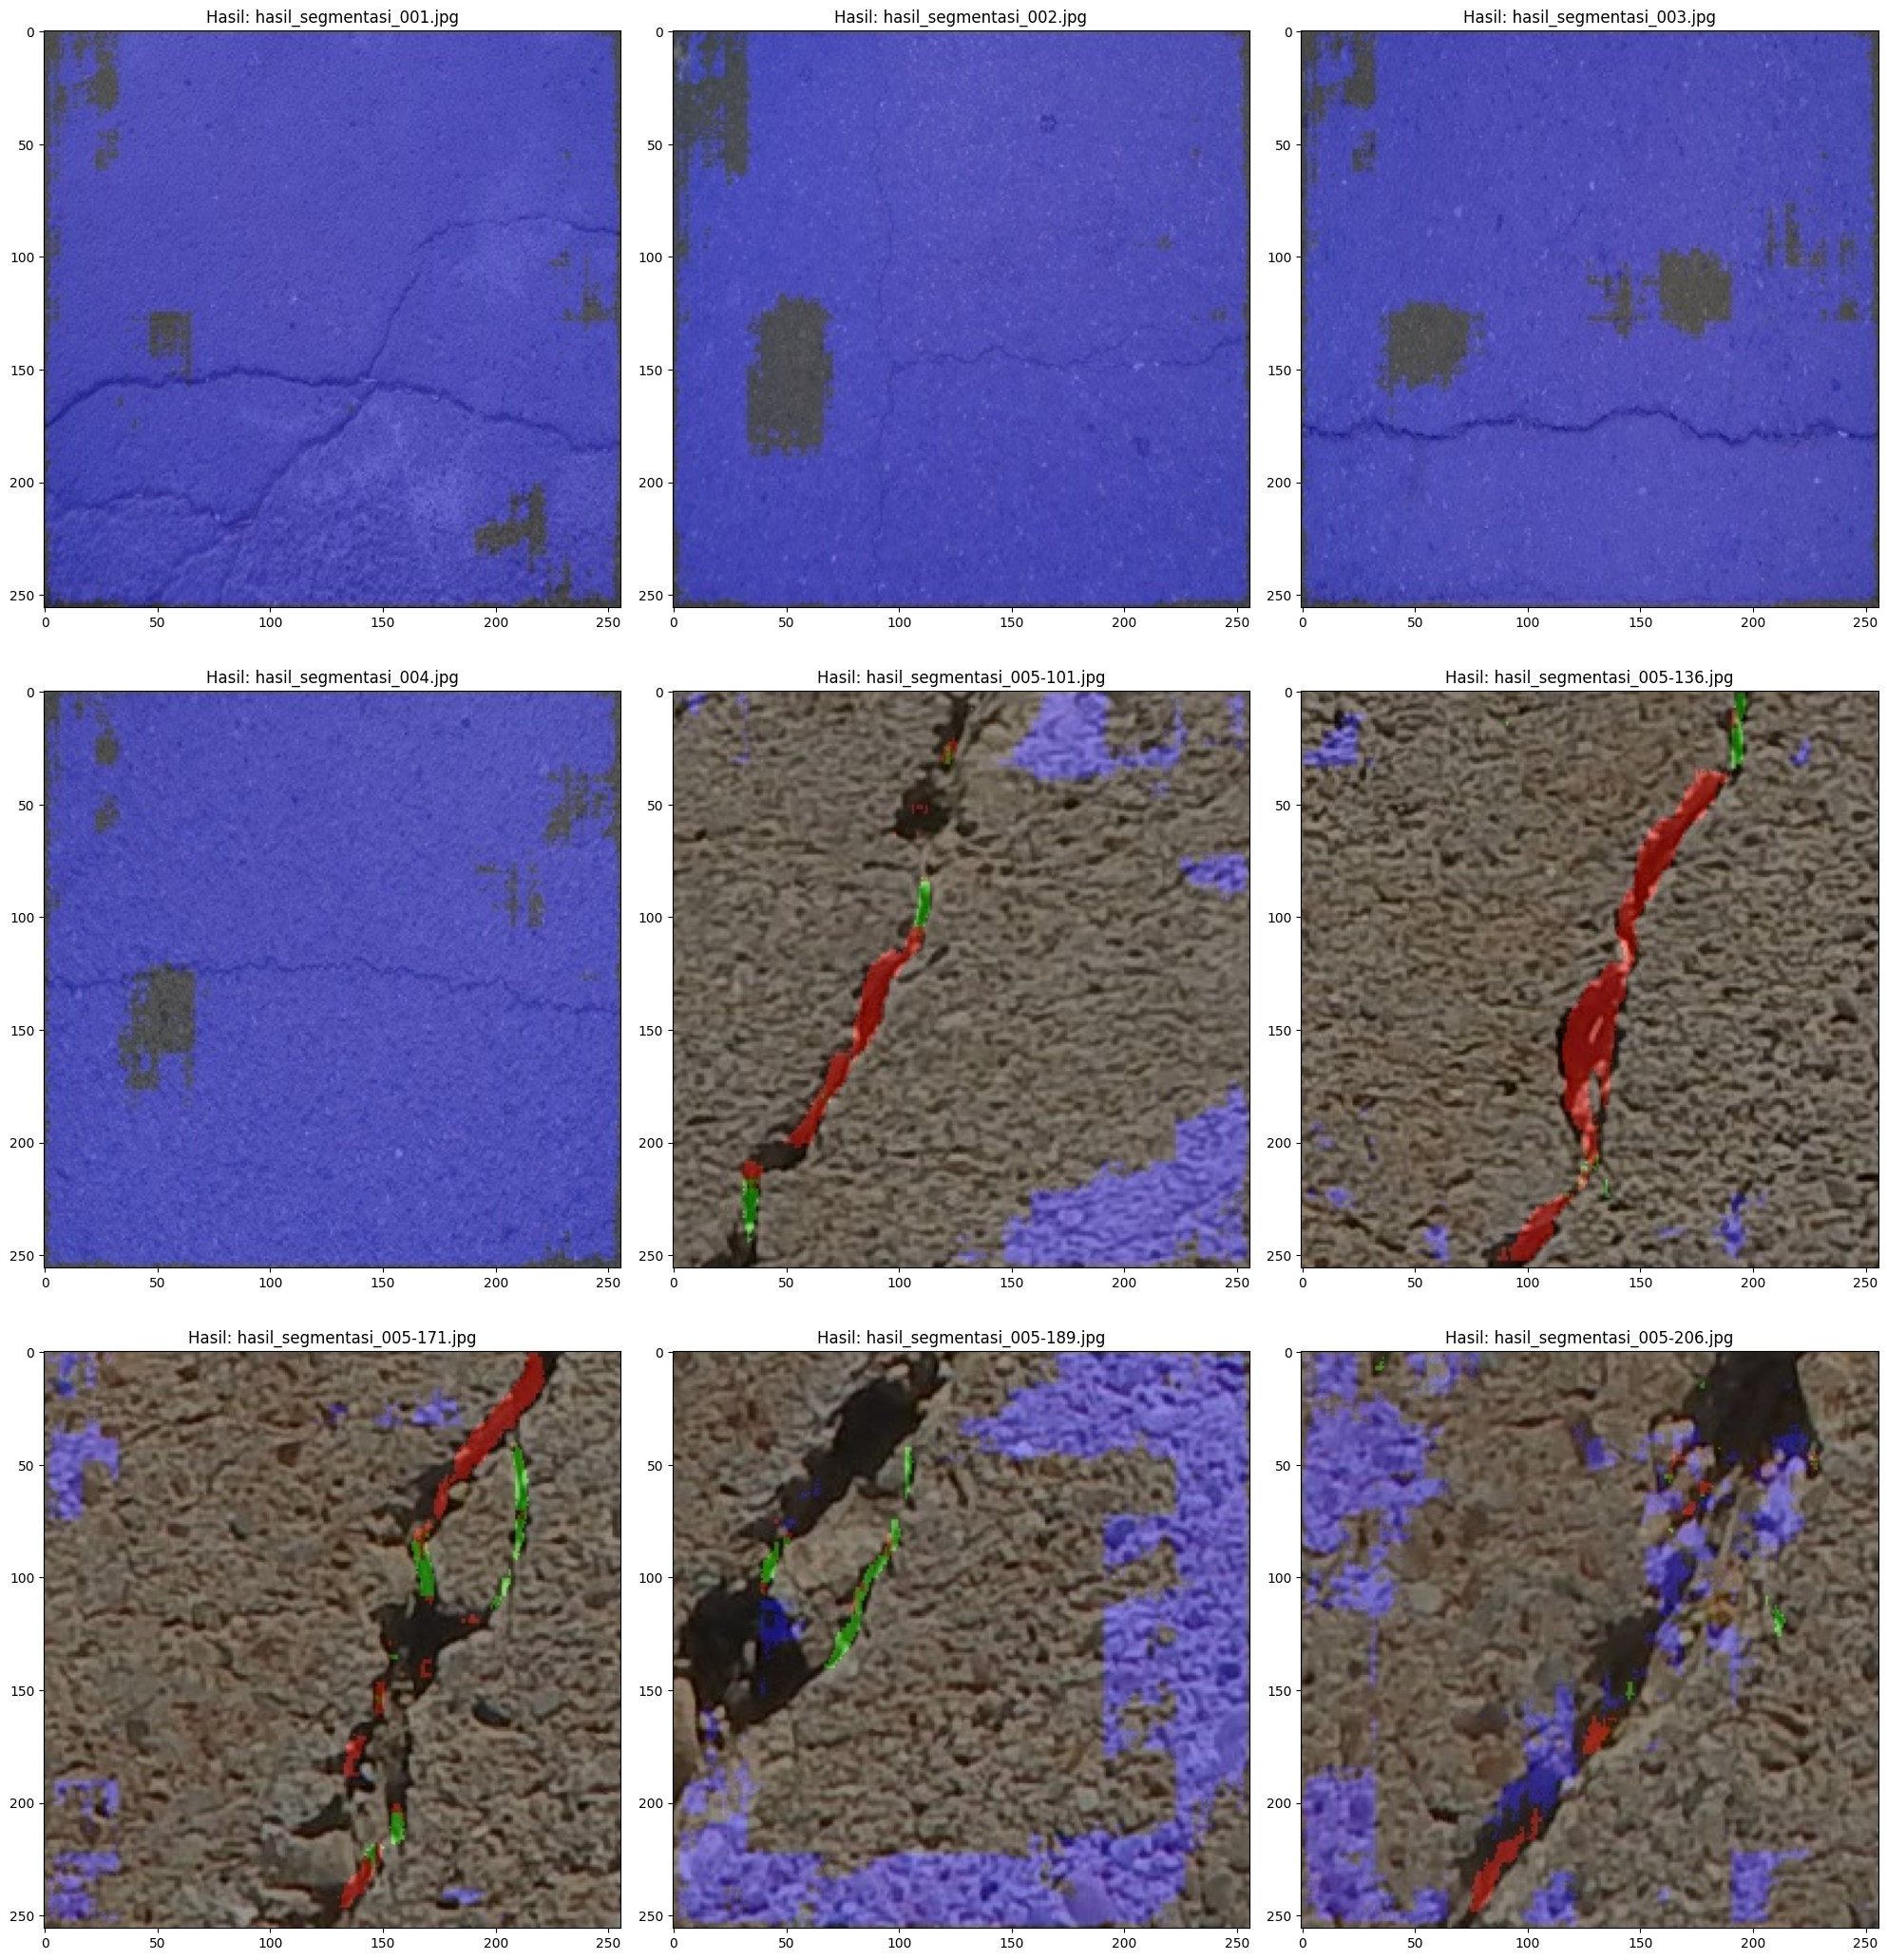


Visualisasi sampel hasil inferensi selesai


In [32]:
OUTPUT_DIR = "results_segmentation_fcn" 
NUM_TO_SHOW = 9 # Tampilkan gambar pertama

print(f"Memuat hasil gambar dari folder '{OUTPUT_DIR}' untuk ditampilkan...")

# Cari File Hasil
# Cari semua file yang disimpan
result_paths = glob.glob(os.path.join(OUTPUT_DIR, "hasil_segmentasi_*.jpg")) + \
               glob.glob(os.path.join(OUTPUT_DIR, "hasil_segmentasi_*.jpeg")) + \
               glob.glob(os.path.join(OUTPUT_DIR, "hasil_segmentasi_*.png"))
result_paths.sort() # Urutkan berdasarkan nama file

# Periksa & Tampilkan
if not result_paths:
    print(f"Tidak ada file hasil yang ditemukan di folder '{OUTPUT_DIR}'")
    print("Pastikan Inference Otomatis sudah dijalankan")
else:
    print(f"Ditemukan {len(result_paths)} hasil. Menampilkan {min(NUM_TO_SHOW, len(result_paths))} gambar pertama.")
    
    images_to_show = result_paths[:NUM_TO_SHOW]
    
    # Siapkan plot (3 kolom)
    num_rows = int(np.ceil(len(images_to_show) / 3))
    plt.figure(figsize=(20, num_rows * 7)) # Buat figur yang besar

    for i, img_path in enumerate(images_to_show):
        try:
            # Muat gambar (OpenCV memuat sebagai BGR)
            img_bgr = cv2.imread(img_path)
            if img_bgr is None:
                print(f"Gagal memuat {img_path}")
                continue
            
            # Konversi ke RGB untuk ditampilkan dengan Matplotlib
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            
            # Tampilkan gambar
            plt.subplot(num_rows, 3, i + 1)
            plt.imshow(img_rgb)
            plt.title(f"Hasil: {os.path.basename(img_path)}")
            plt.axis("on")

        except Exception as e:
            print(f"Gagal menampilkan {img_path}: {e}")
            
    plt.tight_layout()
    plt.show()

print("\nVisualisasi sampel hasil inferensi selesai")